# Phase 4: PICO Simulation and Scenario Analysis
**GLP-1 RCT Evidence Pipeline**

This notebook runs six scenario analyses on the structured trial database produced in Phase 3:

1. **Data Exploration** — shape, missingness, distributions across all key variables
2. **Women-Specific Evidence** — female enrollment, women-only trials, sex-stratified outcomes
3. **Indication Landscape** — obesity, T2D, cardiovascular, NASH
4. **Comparator Gap Analysis** — head-to-head vs. placebo-only, per drug
5. **Outcome Heterogeneity** — weight loss, HbA1c, MACE definition fragmentation + standardization
6. **Patient-Centeredness Classification** — surrogate vs. patient-centered outcome distribution *(new)*
7. **Population Subgroup Representation** — sex, race/ethnicity, age, renal/hepatic impairment *(new)*
7b. **Longitudinal Gap Targeting** — drug×indication follow-up heatmap *(new)*
7c. **Race/Ethnicity Reporting by Drug** — FDA diversity context *(new)*
8. **Evidence Sufficiency Scoring**
9. **SNOMED-CT Outcome Landscape** — terminology-grounded comprehensiveness analysis *(new)*
10. **Manuscript Preparation Summary** — manuscript-ready statistics *(new)* — terminology-grounded comprehensiveness analysis *(new)* — per-scenario rubric-based scoring

---
> **Prerequisites:** `glp1_database.xlsx` in the same directory as this notebook (output of Phase 3).

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import re
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", "{:.1f}".format)

# ── Load database ─────────────────────────────────────────────────────────────
DB_PATH  = "glp1_database.xlsx"
DB_SHEET = "All Trials"

df = pd.read_excel(DB_PATH, sheet_name=DB_SHEET)
df.columns = [c.lower().strip().replace(" ", "_") for c in df.columns]

print(f"Loaded {len(df):,} trials")
print(f"Columns: {df.columns.tolist()}")

Loaded 2,392 trials
Columns: ['pmid', 'pmcid', 'title', 'abstract', 'full_text', 'text_source', 'year', 'journal', 'authors', 'pub_types', 'mesh_terms', 'indication_hint', 'population', 'intervention', 'comparison', 'outcomes_primary', 'outcomes_secondary', 'extraction_notes', 'extraction_status', 'indication', 'trial_phase', 'enrollment_size', 'female_pct', 'follow_up_duration', 'comparator_type', 'women_only_trial', 'sex_stratified_outcomes', 'female_enrollment_reported', 'subgroup_elderly', 'subgroup_pediatric', 'subgroup_racial_ethnic', 'subgroup_sex_specific', 'subgroup_renal_hepatic', 'subgroup_other', 'patient_centered_outcomes', 'surrogate_outcomes', 'patient_centeredness_flag', 'annotation_status', 'drug_name', 'indication_clean', 'has_any_subgroup', 'missing_subgroups', 'nct_id', 'ct_status', 'ct_phase', 'ct_enrollment']


In [2]:
# ── Column name mapping (corrected for actual glp1_database.csv columns) ──────
COL = {
    "drug":            "drug_name",
    "indication":      "indication_clean",
    "comparator_type": "comparator_type",
    "comparator":      "comparison",
    "female_pct":      "female_pct",
    "women_only":      "women_only_trial",
    "sex_stratified":  "sex_stratified_outcomes",
    "enrollment":      "enrollment_size",
    "followup":        "follow_up_duration",
    "primary_outcome": "outcomes_primary",
    # ── Subgroup columns (fixed — actual annotate.py output column names) ──────
    "subgroup":        "has_any_subgroup",        # bool: any subgroup data present
    "race":            "subgroup_racial_ethnic",  # yes/no/unclear/partial
    "age_strat":       "subgroup_sex_specific",   # closest proxy; sex-specific analyses
    "renal":           "subgroup_renal_hepatic",  # covers both renal and hepatic
    "hepatic":         "subgroup_renal_hepatic",  # same column
    "pediatric":       "subgroup_pediatric",
    "elderly":         "subgroup_elderly",
}

def col(key):
    name = COL.get(key, key)
    return name if name in df.columns else None

# ── Numeric coercions ─────────────────────────────────────────────────────────
for k in ["female_pct", "enrollment"]:
    c = col(k)
    if c:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# ── Boolean coercions (stored as 'yes'/'no'/'unclear') ────────────────────────
def coerce_bool(series):
    s = series.astype(str).str.strip().str.lower()
    return s.isin(["yes", "true", "1", "t", "y"])

bool_keys = ["women_only", "sex_stratified", "subgroup"]
for k in bool_keys:
    c = col(k)
    if c:
        df[c] = coerce_bool(df[c])

# ── Subgroup string columns — leave as-is for Analysis 7 value detection ──────
# subgroup_racial_ethnic, subgroup_elderly, subgroup_pediatric,
# subgroup_renal_hepatic, subgroup_sex_specific are stored as yes/no/unclear strings

# ── Parse follow-up to months ─────────────────────────────────────────────────
def parse_followup_months(val):
    if pd.isna(val): return np.nan
    s = str(val).lower().strip()
    if s in ("nr", "not reported", "nan", ""): return np.nan
    m = re.search(r"([\d.]+)\s*week",  s)
    if m: return float(m.group(1)) / 4.33
    m = re.search(r"([\d.]+)\s*month", s)
    if m: return float(m.group(1))
    m = re.search(r"([\d.]+)\s*year",  s)
    if m: return float(m.group(1)) * 12
    m = re.search(r"([\d.]+)\s*day",   s)
    if m: return float(m.group(1)) / 30
    return np.nan

fu_c = col("followup")
if fu_c:
    df["followup_months"] = df[fu_c].apply(parse_followup_months)

# ── Confirm which subgroup columns are present ────────────────────────────────
print("Column mapping and coercions complete.")
print(f"Follow-up months parsed for {df['followup_months'].notna().sum():,} / {len(df):,} trials")
print()
print("Subgroup column availability:")
for key in ["subgroup", "race", "age_strat", "renal", "pediatric", "elderly"]:
    c = col(key)
    status = f"FOUND ({c})" if c else f"MISSING (looked for: {COL.get(key, key)})"
    print(f"  {key:<12} → {status}")


Column mapping and coercions complete.
Follow-up months parsed for 1,556 / 2,392 trials

Subgroup column availability:
  subgroup     → FOUND (has_any_subgroup)
  race         → FOUND (subgroup_racial_ethnic)
  age_strat    → FOUND (subgroup_sex_specific)
  renal        → FOUND (subgroup_renal_hepatic)
  pediatric    → FOUND (subgroup_pediatric)
  elderly      → FOUND (subgroup_elderly)


---
## Analysis 1: Data Exploration
Shape, missingness, and distributions across all key variables.

In [3]:
# ── Shape and dtypes ──────────────────────────────────────────────────────────
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns\n")
print("Column dtypes:")
print(df.dtypes.to_string())

Shape: 2,392 rows × 47 columns

Column dtypes:
pmid                            int64
pmcid                             str
title                             str
abstract                          str
full_text                         str
text_source                       str
year                            int64
journal                           str
authors                           str
pub_types                         str
mesh_terms                        str
indication_hint                   str
population                        str
intervention                      str
comparison                        str
outcomes_primary                  str
outcomes_secondary                str
extraction_notes                  str
extraction_status                 str
indication                        str
trial_phase                       str
enrollment_size               float64
female_pct                    float64
follow_up_duration                str
comparator_type                   str
wom

Missing data by column:


,N Missing,% Missing,N Present
female_pct,1574,65.8,818
ct_phase,1472,61.5,920
pmcid,1432,59.9,960
ct_enrollment,1174,49.1,1218
ct_status,1173,49.0,1219
nct_id,1173,49.0,1219
indication_hint,983,41.1,1409
followup_months,836,34.9,1556
outcomes_secondary,353,14.8,2039
enrollment_size,219,9.2,2173


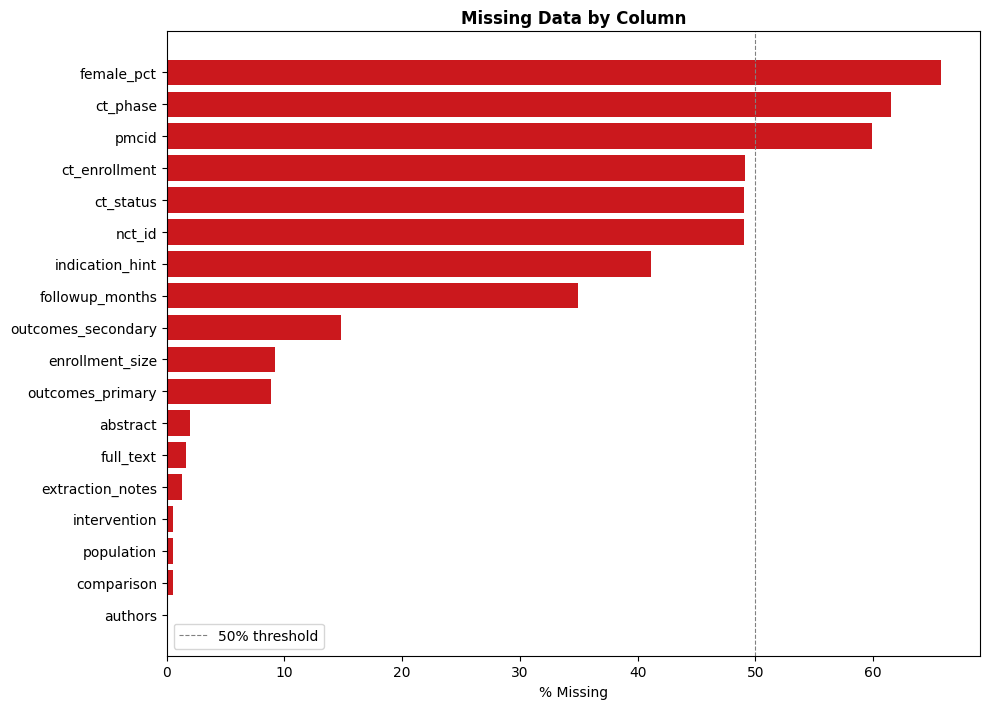

In [4]:
# ── Missing data overview ─────────────────────────────────────────────────────
missing = pd.DataFrame({
    "N Missing":  df.isna().sum(),
    "% Missing":  (df.isna().mean() * 100).round(1),
    "N Present":  df.notna().sum(),
}).sort_values("% Missing", ascending=False)

print("Missing data by column:")
display(missing)

cols_with_missing = missing[missing["N Missing"] > 0]
if len(cols_with_missing):
    fig, ax = plt.subplots(figsize=(10, max(3, len(cols_with_missing) * 0.4)))
    ax.barh(cols_with_missing.index[::-1], cols_with_missing["% Missing"][::-1], color="#cb181d")
    ax.set_xlabel("% Missing")
    ax.set_title("Missing Data by Column", fontweight="bold")
    ax.axvline(50, color="gray", linestyle="--", linewidth=0.8, label="50% threshold")
    ax.legend()
    plt.tight_layout()
    plt.show()

In [5]:
# ── Sample rows ───────────────────────────────────────────────────────────────
print("First 5 rows (key columns):")
key_cols = [c for c in ["drug_name", "indication_clean", "comparator_type",
                         "female_pct", "enrollment_size", "follow_up_duration",
                         "women_only_trial", "sex_stratified_outcomes"] if c in df.columns]
display(df[key_cols].head())

First 5 rows (key columns):


,drug_name,indication_clean,comparator_type,female_pct,enrollment_size,follow_up_duration,women_only_trial,sex_stratified_outcomes
0,Other/NR,Obesity,Placebo,0.0,8.0,8 hours,False,False
1,Other/NR,Type 2 Diabetes,Placebo,NaN,6.0,48 hours,False,False
2,Other/NR,Other/NR,Placebo,NaN,8.0,NR,False,False
3,Other/NR,Type 2 Diabetes,Dose Comparison,NaN,15.0,4 hours,False,False
4,Other/NR,Other/NR,Placebo,0.0,6.0,6 hours,False,False


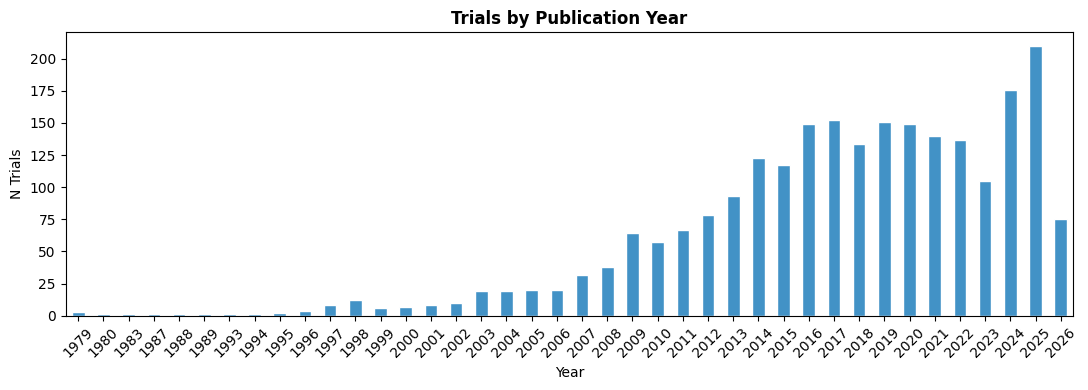

Year range: 1979 – 2026   |   Median: 2018


In [6]:
# ── Publication year distribution ─────────────────────────────────────────────
if "year" in df.columns:
    year_s = pd.to_numeric(df["year"], errors="coerce").dropna()
    fig, ax = plt.subplots(figsize=(11, 4))
    year_s.value_counts().sort_index().plot(kind="bar", ax=ax, color="#4292c6", edgecolor="white")
    ax.set_title("Trials by Publication Year", fontweight="bold")
    ax.set_xlabel("Year"); ax.set_ylabel("N Trials")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()
    print(f"Year range: {int(year_s.min())} – {int(year_s.max())}   |   Median: {int(year_s.median())}")

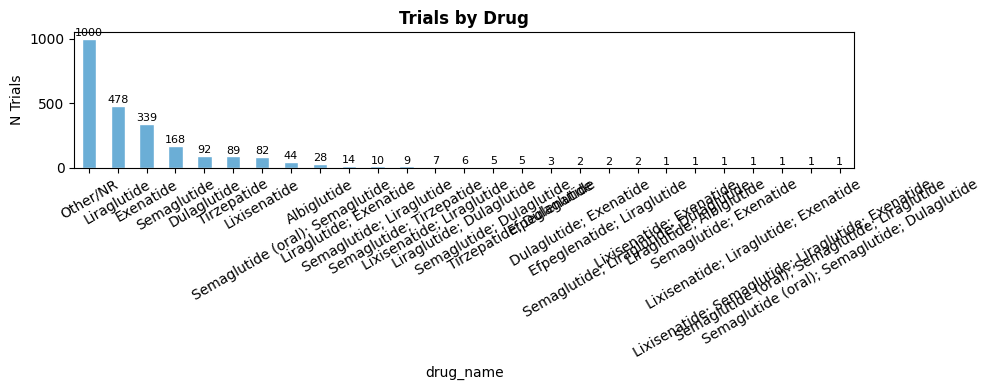

drug_name
Other/NR                                             1000
Liraglutide                                           478
Exenatide                                             339
Semaglutide                                           168
Dulaglutide                                            92
Tirzepatide                                            89
Lixisenatide                                           82
Semaglutide (oral); Semaglutide                        44
Albiglutide                                            28
Liraglutide; Exenatide                                 14
Semaglutide; Liraglutide                               10
Semaglutide; Tirzepatide                                9
Lixisenatide; Liraglutide                               7
Liraglutide; Dulaglutide                                6
Semaglutide; Dulaglutide                                5
Tirzepatide; Dulaglutide                                5
Efpeglenatide                                           3
Dula

In [7]:
# ── Drug distribution ─────────────────────────────────────────────────────────
drug_col = col("drug")
if drug_col:
    drug_counts = df[drug_col].value_counts()
    fig, ax = plt.subplots(figsize=(10, 4))
    drug_counts.plot(kind="bar", ax=ax, color="#6baed6", edgecolor="white")
    ax.set_title("Trials by Drug", fontweight="bold"); ax.set_ylabel("N Trials")
    ax.tick_params(axis="x", rotation=30)
    for bar in ax.patches:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                str(int(bar.get_height())), ha="center", va="bottom", fontsize=8)
    plt.tight_layout(); plt.show()
    print(drug_counts.to_string())

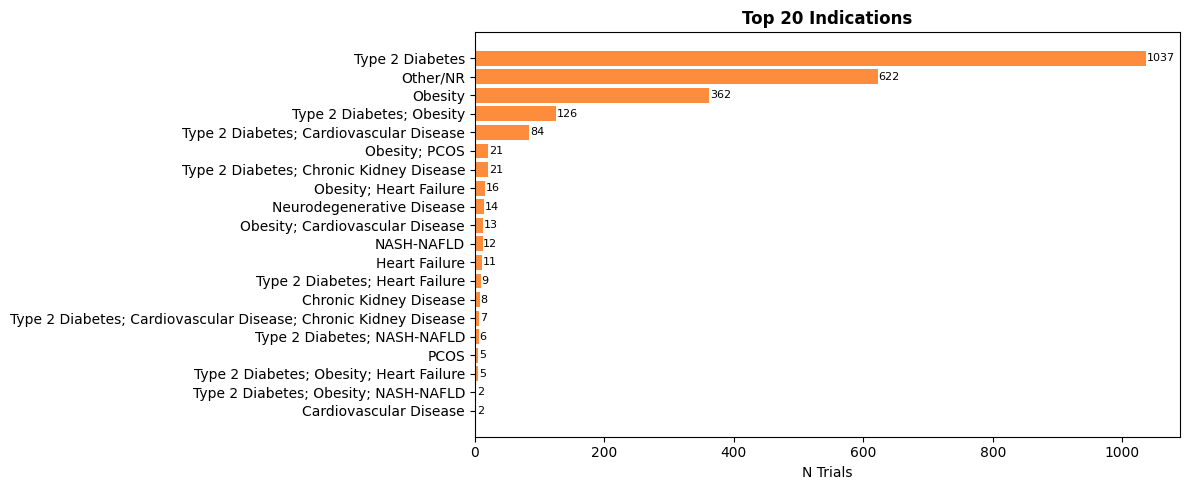

In [8]:
# ── Indication distribution (top 20) ─────────────────────────────────────────
ind_col = col("indication")
if ind_col:
    ind_counts = df[ind_col].value_counts().head(20)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.barh(ind_counts.index[::-1], ind_counts.values[::-1], color="#fd8d3c")
    ax.set_title("Top 20 Indications", fontweight="bold"); ax.set_xlabel("N Trials")
    for i, v in enumerate(ind_counts.values[::-1]):
        ax.text(v + 1, i, str(v), va="center", fontsize=8)
    plt.tight_layout(); plt.show()

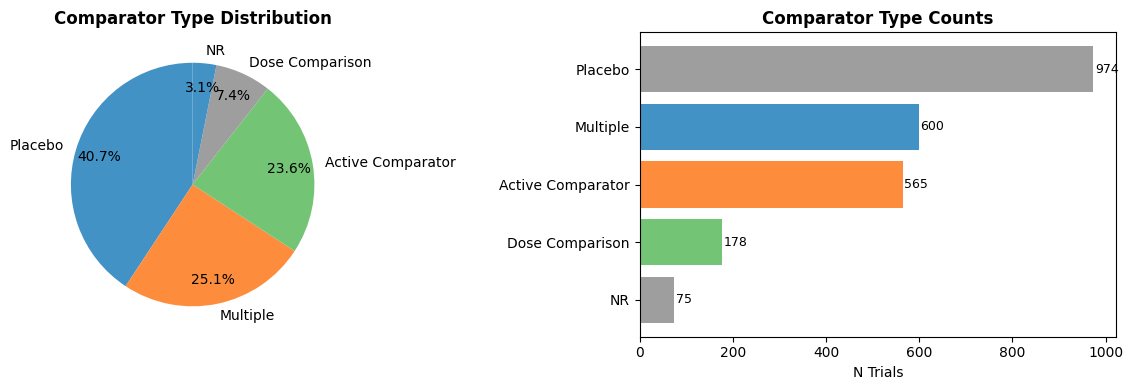

In [9]:
# ── Comparator type distribution ──────────────────────────────────────────────
comp_col = col("comparator_type")
if comp_col:
    comp_counts = df[comp_col].value_counts()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].pie(comp_counts.values, labels=comp_counts.index, autopct="%1.1f%%",
                colors=["#4292c6", "#fd8d3c", "#74c476", "#9e9e9e"], startangle=90, pctdistance=0.8)
    axes[0].set_title("Comparator Type Distribution", fontweight="bold")
    axes[1].barh(comp_counts.index[::-1], comp_counts.values[::-1],
                 color=["#4292c6", "#fd8d3c", "#74c476", "#9e9e9e"][::-1])
    axes[1].set_xlabel("N Trials"); axes[1].set_title("Comparator Type Counts", fontweight="bold")
    for i, v in enumerate(comp_counts.values[::-1]):
        axes[1].text(v + 3, i, str(v), va="center", fontsize=9)
    plt.tight_layout(); plt.show()

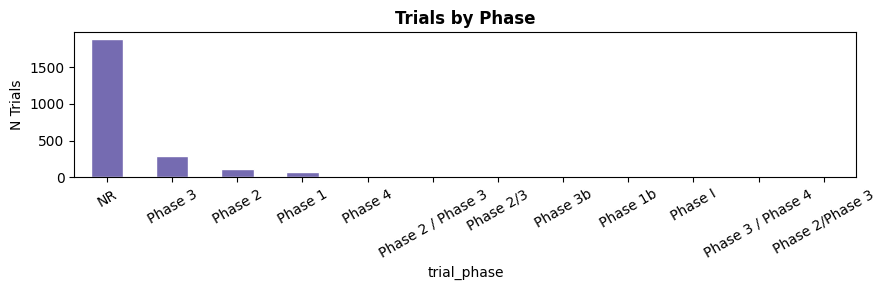

In [10]:
# ── Trial phase distribution ──────────────────────────────────────────────────
if "trial_phase" in df.columns:
    phase_counts = df["trial_phase"].value_counts()
    fig, ax = plt.subplots(figsize=(9, 3))
    phase_counts.plot(kind="bar", ax=ax, color="#756bb1", edgecolor="white")
    ax.set_title("Trials by Phase", fontweight="bold"); ax.set_ylabel("N Trials")
    ax.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.show()

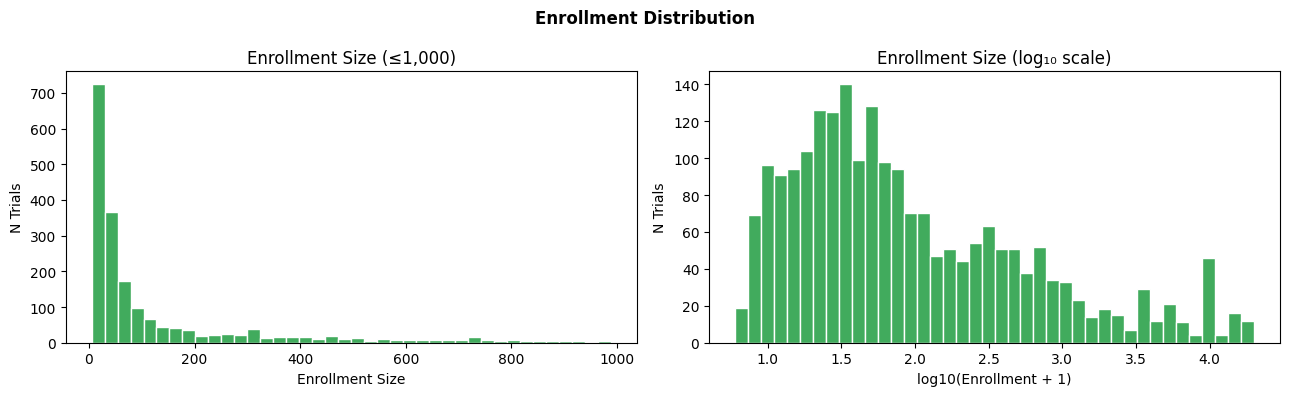

Enrollment — N: 2,173  |  Median: 54  |  Mean: 794  |  Max: 20000
Trials with n≥500:  400
Trials with n≥1000: 258


In [11]:
# ── Enrollment size distribution ──────────────────────────────────────────────
enr_col = col("enrollment")
if enr_col:
    enr = df[enr_col].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(enr[enr <= 1000], bins=40, color="#41ab5d", edgecolor="white")
    axes[0].set_title("Enrollment Size (≤1,000)"); axes[0].set_xlabel("Enrollment Size"); axes[0].set_ylabel("N Trials")
    axes[1].hist(np.log10(enr + 1), bins=40, color="#41ab5d", edgecolor="white")
    axes[1].set_title("Enrollment Size (log₁₀ scale)"); axes[1].set_xlabel("log10(Enrollment + 1)"); axes[1].set_ylabel("N Trials")
    plt.suptitle("Enrollment Distribution", fontweight="bold"); plt.tight_layout(); plt.show()
    print(f"Enrollment — N: {len(enr):,}  |  Median: {enr.median():.0f}  |  Mean: {enr.mean():.0f}  |  Max: {enr.max():.0f}")
    print(f"Trials with n≥500:  {(enr>=500).sum():,}")
    print(f"Trials with n≥1000: {(enr>=1000).sum():,}")

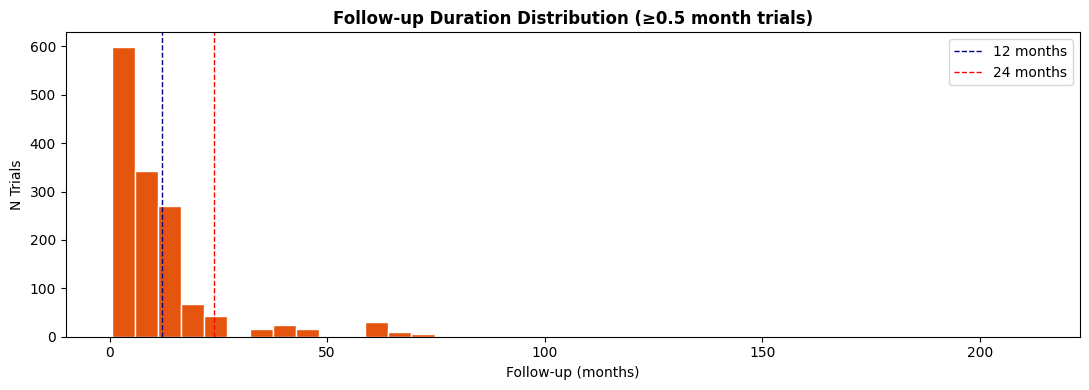

Follow-up — N parsed: 1,556  |  Median: 6.0 mo  |  Trials ≥12 mo: 487  |  Trials ≥24 mo: 148


In [12]:
# ── Follow-up duration distribution ──────────────────────────────────────────
if "followup_months" in df.columns:
    fu = df["followup_months"].dropna()
    fu_clinical = fu[fu >= 0.5]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.hist(fu_clinical, bins=40, color="#e6550d", edgecolor="white")
    ax.set_title("Follow-up Duration Distribution (≥0.5 month trials)", fontweight="bold")
    ax.set_xlabel("Follow-up (months)"); ax.set_ylabel("N Trials")
    ax.axvline(12, color="navy",  linestyle="--", linewidth=1, label="12 months")
    ax.axvline(24, color="red",   linestyle="--", linewidth=1, label="24 months")
    ax.legend(); plt.tight_layout(); plt.show()
    print(f"Follow-up — N parsed: {len(fu):,}  |  Median: {fu.median():.1f} mo  |  "
          f"Trials ≥12 mo: {(fu>=12).sum():,}  |  Trials ≥24 mo: {(fu>=24).sum():,}")

In [13]:
# ── Numeric summary statistics ────────────────────────────────────────────────
numeric_cols = list(dict.fromkeys(df.select_dtypes(include="number").columns.tolist()
                                  + (["followup_months"] if "followup_months" in df.columns else [])))
print("Descriptive statistics (numeric columns):")
display(df[numeric_cols].describe().round(1))

Descriptive statistics (numeric columns):


,pmid,year,enrollment_size,female_pct,ct_enrollment,followup_months
count,2392.0,2392.0,2173.0,818.0,1218.0,1556.0
mean,29504705.3,2017.2,793.7,40.0,1699.2,9.9
std,7823670.1,6.5,2443.3,31.3,15144.6,13.8
min,91023.0,1979.0,5.0,0.0,0.0,0.0
25%,24393557.2,2014.0,20.0,0.0,36.0,2.8
50%,29706221.5,2018.0,54.0,40.6,102.5,6.0
75%,35840065.5,2022.0,295.0,60.0,469.0,12.0
max,42139606.0,2026.0,20000.0,100.0,451036.0,212.4


---
## Analysis 2: Women-Specific Evidence Landscape
Filter to high female-enrollment trials (≥50% female); characterize available evidence; identify gaps.

WOMEN-SPECIFIC EVIDENCE SUMMARY
  Total trials in database:              2,392
  Female % reported for:                 818 trials (34.2%)
  Mean female enrollment (where reported): 40.0%
  Trials with ≥50% female enrollment:   305
  Women-only trials:                     80
  Trials with sex-stratified outcomes:   100


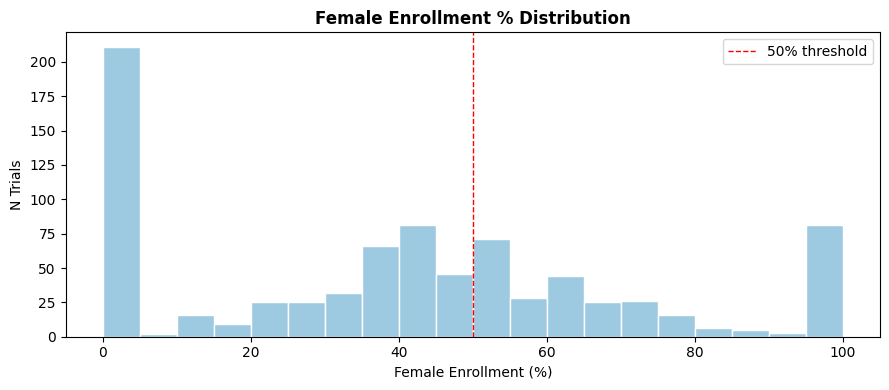

In [14]:
female_col     = col("female_pct")
women_only_col = col("women_only")
sex_strat_col  = col("sex_stratified")

high_female = df[df[female_col] >= 50].copy()       if female_col     else pd.DataFrame()
women_only  = df[df[women_only_col] == True].copy() if women_only_col else pd.DataFrame()

print("=" * 55)
print("WOMEN-SPECIFIC EVIDENCE SUMMARY")
print("=" * 55)
print(f"  Total trials in database:              {len(df):,}")
if female_col:
    print(f"  Female % reported for:                 {int(df[female_col].notna().sum()):,} trials "
          f"({df[female_col].notna().mean()*100:.1f}%)")
    fp = df[female_col].dropna()
    print(f"  Mean female enrollment (where reported): {fp.mean():.1f}%")
    print(f"  Trials with ≥50% female enrollment:   {len(high_female):,}")
if women_only_col:
    print(f"  Women-only trials:                     {len(women_only):,}")
if sex_strat_col:
    print(f"  Trials with sex-stratified outcomes:   {int(df[sex_strat_col].sum()):,}")

# Female % histogram
if female_col and len(fp) > 0:
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(fp, bins=20, color="#9ecae1", edgecolor="white")
    ax.axvline(50, color="red", linestyle="--", linewidth=1, label="50% threshold")
    ax.set_title("Female Enrollment % Distribution", fontweight="bold")
    ax.set_xlabel("Female Enrollment (%)"); ax.set_ylabel("N Trials"); ax.legend()
    plt.tight_layout(); plt.show()

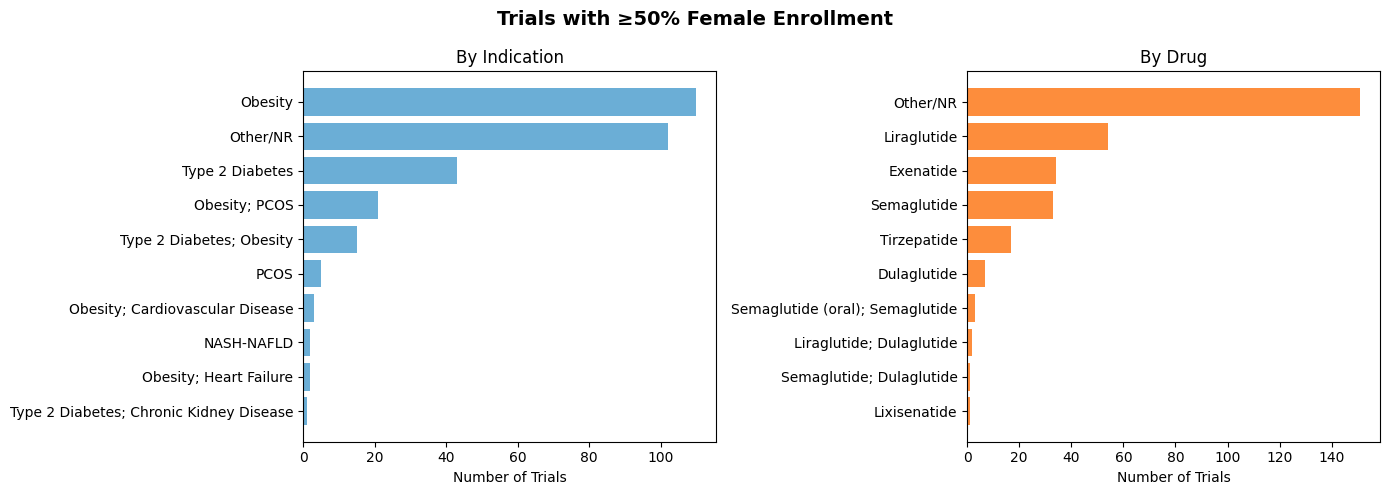


Drugs with NO trials at ≥50% female enrollment:
  - Albiglutide
  - Dulaglutide; Exenatide
  - Efpeglenatide
  - Efpeglenatide; Liraglutide
  - Liraglutide; Albiglutide
  - Liraglutide; Exenatide
  - Lixisenatide; Exenatide
  - Lixisenatide; Liraglutide
  - Lixisenatide; Liraglutide; Exenatide
  - Lixisenatide; Semaglutide; Liraglutide; Exenatide
  - Semaglutide (oral); Semaglutide; Dulaglutide
  - Semaglutide (oral); Semaglutide; Liraglutide
  - Semaglutide; Exenatide
  - Semaglutide; Liraglutide; Dulaglutide
  - Tirzepatide; Dulaglutide


In [15]:
drug_col = col("drug"); ind_col = col("indication")

if len(high_female) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Trials with ≥50% Female Enrollment", fontsize=14, fontweight="bold")
    if ind_col:
        ind_counts = high_female[ind_col].value_counts().head(10)
        axes[0].barh(ind_counts.index[::-1], ind_counts.values[::-1], color="#6baed6")
        axes[0].set_title("By Indication"); axes[0].set_xlabel("Number of Trials")
    if drug_col:
        drug_counts = high_female[drug_col].value_counts().head(10)
        axes[1].barh(drug_counts.index[::-1], drug_counts.values[::-1], color="#fd8d3c")
        axes[1].set_title("By Drug"); axes[1].set_xlabel("Number of Trials")
    plt.tight_layout(); plt.show()

    if drug_col:
        all_drugs    = set(df[drug_col].dropna().unique())
        female_drugs = set(high_female[drug_col].dropna().unique())
        gap_drugs    = all_drugs - female_drugs
        print("\nDrugs with NO trials at ≥50% female enrollment:")
        for d in sorted(gap_drugs):
            print(f"  - {d}")

---
## Analysis 3: Indication Landscape
Compare PICO patterns across obesity, T2D, cardiovascular, and NASH indications.

In [16]:
TARGET_INDICATIONS = {
    "Obesity":        "obesity",
    "T2D":            "type 2 diabetes|type 2|t2d",
    "Cardiovascular": "cardiovascular|cardiac|heart failure",
    "NASH":           "nash|nafld|mash|masld",
}

ind_col  = col("indication"); drug_col = col("drug")
enr_col  = col("enrollment"); comp_col = col("comparator_type")
summary_rows = []

for label, pattern in TARGET_INDICATIONS.items():
    subset = df[df[ind_col].str.contains(pattern, case=False, na=False, regex=True)] if ind_col else pd.DataFrame()
    row = {"Indication": label, "N Trials": len(subset)}
    if len(subset) == 0: summary_rows.append(row); continue
    if drug_col:
        vc = subset[drug_col].value_counts()
        row["Top Drug"] = vc.index[0] if len(vc) else "—"
        row["N Drugs"]  = subset[drug_col].nunique()
    if enr_col:
        row["Median Enrollment"] = int(subset[enr_col].median()) if not subset[enr_col].isna().all() else np.nan
    if "followup_months" in df.columns:
        fu = subset["followup_months"]
        row["Median Follow-up (mo)"] = round(fu.median(), 1) if not fu.isna().all() else np.nan
    if comp_col:
        row["Active Comparator"] = int(subset[comp_col].str.contains("Active Comparator", case=False, na=False).sum())
        row["Placebo"]           = int(subset[comp_col].str.contains("Placebo",           case=False, na=False).sum())
        row["Dose Comparison"]   = int(subset[comp_col].str.contains("Dose",              case=False, na=False).sum())
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index("Indication")
print("INDICATION LANDSCAPE SUMMARY")
display(summary_df)

INDICATION LANDSCAPE SUMMARY


,N Trials,Top Drug,N Drugs,Median Enrollment,Median Follow-up (mo),Active Comparator,Placebo,Dose Comparison
Indication,,,,,,,,
Obesity,551,Other/NR,11,60,7.4,99,279,31
T2D,1300,Other/NR,27,117,6.0,404,452,77
Cardiovascular,152,Liraglutide,11,9340,24.0,10,129,1
NASH,22,Liraglutide,6,71,5.5,8,7,1


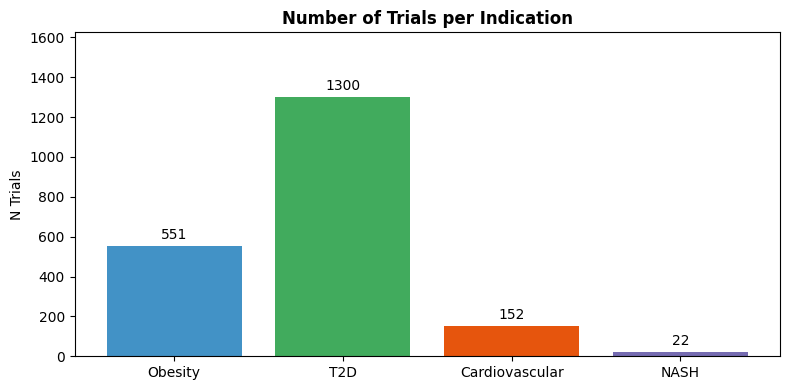

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#4292c6", "#41ab5d", "#e6550d", "#756bb1"]
bars = ax.bar(summary_df.index, summary_df["N Trials"], color=colors)
ax.bar_label(bars, padding=3)
ax.set_title("Number of Trials per Indication", fontweight="bold"); ax.set_ylabel("N Trials")
ax.set_ylim(0, summary_df["N Trials"].max() * 1.25)
plt.tight_layout(); plt.show()

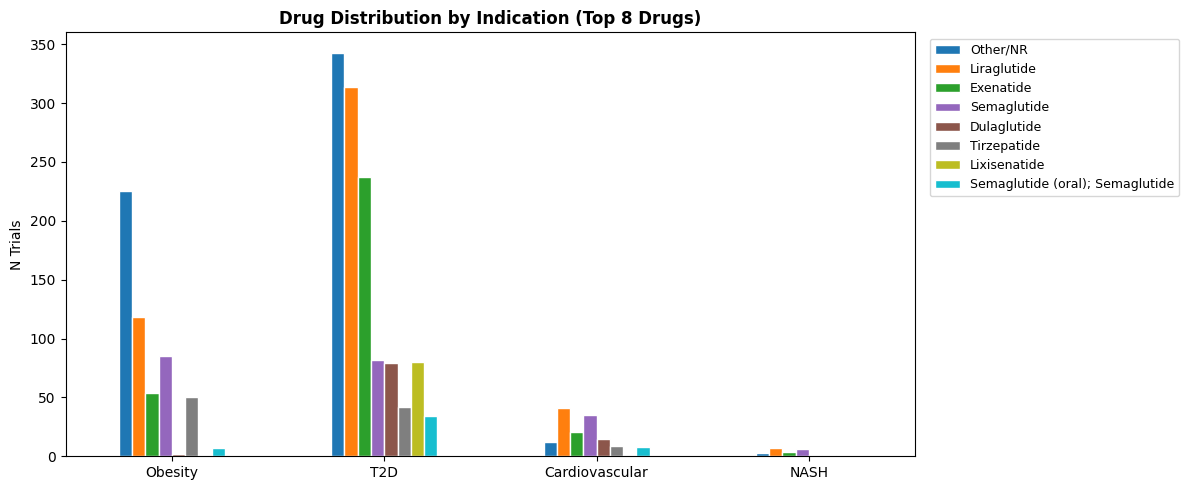

In [18]:
if drug_col and ind_col:
    top_drugs_global = df[drug_col].value_counts().head(8).index.tolist()
    pivot_data = {}
    for label, pattern in TARGET_INDICATIONS.items():
        subset = df[df[ind_col].str.contains(pattern, case=False, na=False, regex=True)]
        counts = subset[drug_col].value_counts()
        pivot_data[label] = {d: counts.get(d, 0) for d in top_drugs_global}
    pivot_df = pd.DataFrame(pivot_data).T
    pivot_df.plot(kind="bar", figsize=(12, 5), colormap="tab10", edgecolor="white")
    plt.title("Drug Distribution by Indication (Top 8 Drugs)", fontweight="bold")
    plt.ylabel("N Trials"); plt.xticks(rotation=0)
    plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
    plt.tight_layout(); plt.show()

---
## Analysis 4: Comparator Gap Analysis
Which GLP-1 agents have head-to-head trial evidence vs. placebo-only?

In [19]:
comp_col = col("comparator_type"); drug_col = col("drug")

if comp_col and drug_col:
    h2h_mask     = df[comp_col].str.contains("Active Comparator", case=False, na=False)
    placebo_mask = df[comp_col].str.contains("Placebo",           case=False, na=False)
    dose_mask    = df[comp_col].str.contains("Dose",              case=False, na=False)

    h2h = df[h2h_mask]; placebo = df[placebo_mask]

    print(f"Total trials:              {len(df):,}")
    print(f"Active comparator (H2H):   {len(h2h):,} ({len(h2h)/len(df)*100:.1f}%)")
    print(f"Placebo-controlled:        {len(placebo):,} ({len(placebo)/len(df)*100:.1f}%)")
    print(f"Dose comparison:           {int(dose_mask.sum()):,}")
    print(f"Not reported / other:      {int((~h2h_mask & ~placebo_mask & ~dose_mask).sum()):,}")

    h2h_drugs          = set(h2h[drug_col].dropna().unique())
    all_drugs          = set(df[drug_col].dropna().unique())
    placebo_only_drugs = all_drugs - h2h_drugs

    print("\nDrugs WITH active-comparator evidence:")
    for d in sorted(h2h_drugs):
        n = h2h[drug_col].value_counts().get(d, 0)
        print(f"  {d:<30}  ({n} trials)")
    print("\nDrugs with NO active-comparator evidence:")
    for d in sorted(placebo_only_drugs):
        print(f"  {d}")

Total trials:              2,392
Active comparator (H2H):   565 (23.6%)
Placebo-controlled:        974 (40.7%)
Dose comparison:           178
Not reported / other:      675

Drugs WITH active-comparator evidence:
  Albiglutide                     (5 trials)
  Dulaglutide                     (26 trials)
  Exenatide                       (111 trials)
  Liraglutide                     (138 trials)
  Liraglutide; Albiglutide        (1 trials)
  Liraglutide; Dulaglutide        (4 trials)
  Liraglutide; Exenatide          (8 trials)
  Lixisenatide                    (27 trials)
  Lixisenatide; Exenatide         (1 trials)
  Lixisenatide; Liraglutide       (6 trials)
  Other/NR                        (171 trials)
  Semaglutide                     (27 trials)
  Semaglutide (oral); Semaglutide  (8 trials)
  Semaglutide (oral); Semaglutide; Dulaglutide  (1 trials)
  Semaglutide; Dulaglutide        (4 trials)
  Semaglutide; Exenatide          (1 trials)
  Semaglutide; Liraglutide        (2 trials

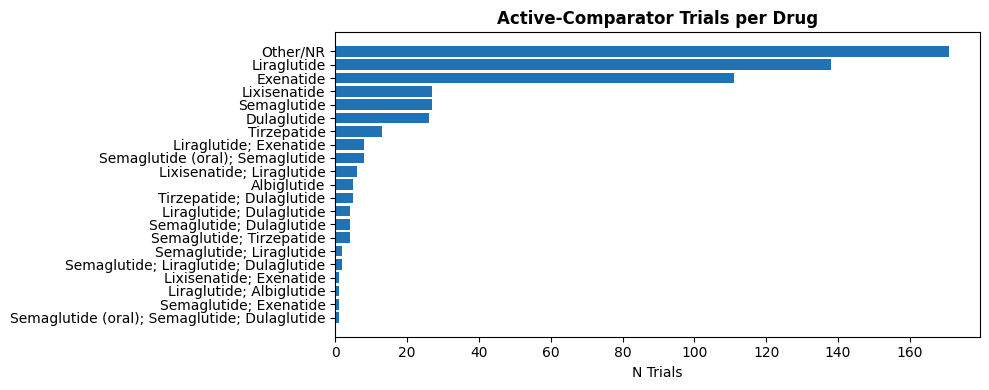

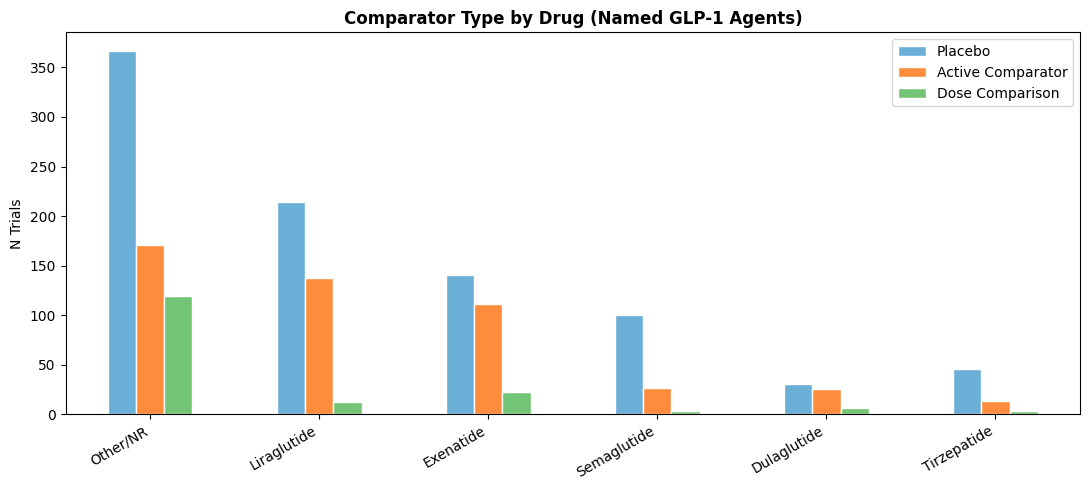

In [20]:
if comp_col and drug_col and len(h2h) > 0:
    h2h_counts = h2h[drug_col].value_counts()
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(h2h_counts.index[::-1], h2h_counts.values[::-1], color="#2171b5")
    ax.set_title("Active-Comparator Trials per Drug", fontweight="bold"); ax.set_xlabel("N Trials")
    plt.tight_layout(); plt.show()

if comp_col and drug_col:
    named_drugs = [d for d in df[drug_col].value_counts().index
                   if d not in ("Other/Unknown", "GLP-1 (unspecified)")][:6]
    comp_pivot = {}
    for drug in named_drugs:
        sub = df[df[drug_col] == drug]
        comp_pivot[drug] = {
            "Placebo":           int(sub[comp_col].str.contains("Placebo",           case=False, na=False).sum()),
            "Active Comparator": int(sub[comp_col].str.contains("Active Comparator", case=False, na=False).sum()),
            "Dose Comparison":   int(sub[comp_col].str.contains("Dose",              case=False, na=False).sum()),
        }
    comp_df = pd.DataFrame(comp_pivot).T
    comp_df.plot(kind="bar", figsize=(11, 5), color=["#6baed6", "#fd8d3c", "#74c476"], edgecolor="white")
    plt.title("Comparator Type by Drug (Named GLP-1 Agents)", fontweight="bold")
    plt.ylabel("N Trials"); plt.xticks(rotation=30, ha="right"); plt.legend()
    plt.tight_layout(); plt.show()

---
## Analysis 5: Outcome Heterogeneity & MACE Standardization
How many distinct definitions are used for weight loss, HbA1c, and MACE?
MACE definitions are clustered into canonical groupings to quantify fragmentation.

In [21]:
OUTCOME_TARGETS = {
    "Weight Loss": r"weight|bmi|body mass|waist",
    "HbA1c":       r"hba1c|glycat|a1c|hemoglobin a",
    "MACE":        r"mace|cardiovascular event|major adverse|cv event|cv death",
}

outcome_col = col("primary_outcome")
heterogeneity_results = {}

if outcome_col:
    for label, pattern in OUTCOME_TARGETS.items():
        matches  = df[df[outcome_col].str.contains(pattern, case=False, na=False, regex=True)]
        raw_defs = matches[outcome_col].dropna().unique()
        heterogeneity_results[label] = {
            "n_trials":   len(matches),
            "n_distinct": len(raw_defs),
            "sample":     raw_defs[:5].tolist(),
        }
    for label, res in heterogeneity_results.items():
        print(f"\n{'='*60}")
        print(f"  {label}")
        print(f"{'='*60}")
        print(f"  Trials mentioning this outcome:  {res['n_trials']:,}")
        print(f"  Distinct raw definitions:        {res['n_distinct']:,}")
        print("  Sample definitions:")
        for d in res["sample"]:
            print(f"    - {str(d)[:115]}")


  Weight Loss
  Trials mentioning this outcome:  261
  Distinct raw definitions:        252
  Sample definitions:
    - Food intake per meal, weight loss
    - Glycemic control (fasting serum glucose, HbA1c), body weight
    - Body weight change
    - Glycaemic control (HbA1c change from baseline); body weight change from baseline
    - Body weight change over 6 months

  HbA1c
  Trials mentioning this outcome:  429
  Distinct raw definitions:        356
  Sample definitions:
    - HbA1c levels; capillary blood glucose (CBG) determinations
    - HbA1c after 12 weeks
    - Glycemic control (fasting serum glucose, HbA1c), body weight
    - HbA1c change from baseline at week 30
    - Change in A1C from baseline at week 30

  MACE
  Trials mentioning this outcome:  49
  Distinct raw definitions:        47
  Sample definitions:
    - Time to primary composite outcome of cardiovascular death, nonfatal myocardial infarction, or nonfatal stroke (MACE
    - First occurrence of any component of

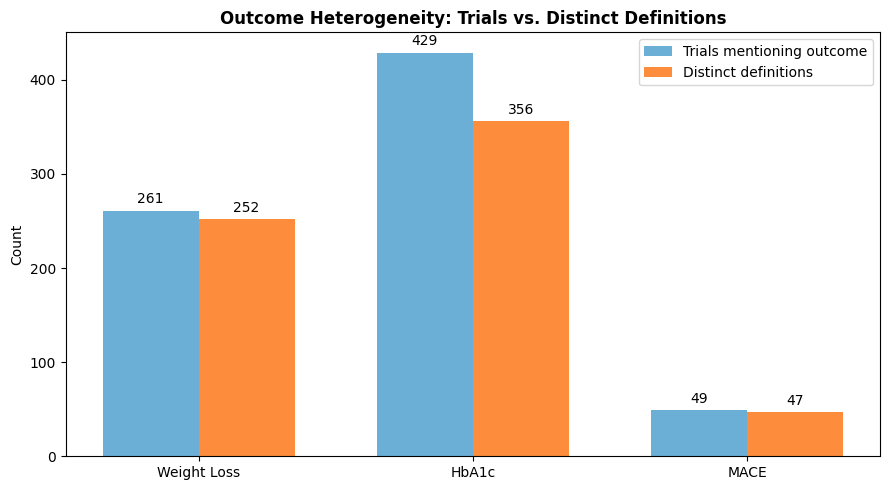

In [22]:
if heterogeneity_results:
    labels     = list(heterogeneity_results.keys())
    n_trials   = [heterogeneity_results[l]["n_trials"]  for l in labels]
    n_distinct = [heterogeneity_results[l]["n_distinct"] for l in labels]
    x = np.arange(len(labels)); width = 0.35
    fig, ax = plt.subplots(figsize=(9, 5))
    b1 = ax.bar(x - width/2, n_trials,   width, label="Trials mentioning outcome", color="#6baed6")
    b2 = ax.bar(x + width/2, n_distinct, width, label="Distinct definitions",      color="#fd8d3c")
    ax.bar_label(b1, padding=3); ax.bar_label(b2, padding=3)
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_title("Outcome Heterogeneity: Trials vs. Distinct Definitions", fontweight="bold")
    ax.set_ylabel("Count"); ax.legend()
    plt.tight_layout(); plt.show()

MACE trials classified:    49
Canonical groups:          7
Reclassified to 3-pt MACE: 5 (CV death only → 3-point via secondary outcomes)



,N Trials
mace_canonical,
Composite MACE (unspecified),17
CV death only,16
"3-point MACE (CV death, MI, stroke) [reclassified]",5
Other/Unclassified,3
"3-point MACE (CV death, MI, stroke)",3
4-point MACE (+ hospitalization),3
MACE + HF,2



Poolability assessment:
  Trials with 3-point MACE (poolable):        8 (16.3%)
  Trials with CV death only (not directly poolable): 16 (32.7%)
  Priority for SNOMED standardization: 16 CV-death-only trials


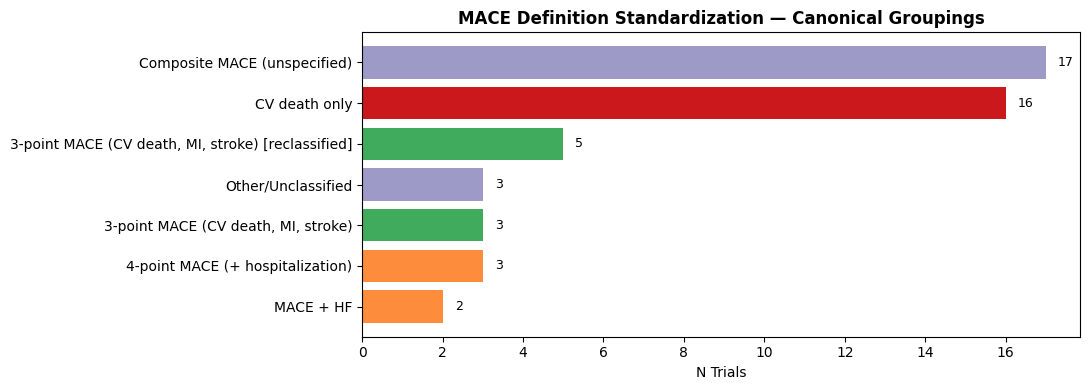


Exported: outputs/mace_standardized.csv  (49 rows)


In [23]:
# ── MACE Standardization (enhanced) ──────────────────────────────────────────
# Cluster free-text MACE definitions into canonical groups.
# NEW: also attempt reclassification of "CV death only" trials where
#      secondary outcomes confirm MI and stroke were also tracked.

MACE_CANONICAL = {
    "3-point MACE (CV death, MI, stroke)":      r"3[- ]?point|3p.mace|cv death.*(mi|myocard).*(stroke|cva)",
    "4-point MACE (+ hospitalization)":         r"4[- ]?point|4p.mace|hospitali[sz]",
    "CV death only":                            r"cardiovascular death|cv death(?!.*mi)(?!.*stroke)",
    "MACE + HF":                                r"heart failure|hf",
    "Composite MACE (unspecified)":             r"composite|mace(?!.*3|.*4|.*death|.*hf)",
    "Major adverse cardiovascular event (NOS)": r"major adverse|mace$|cardiovascular event$",
}

outcome_col   = col("primary_outcome")
secondary_col = "outcomes_secondary" if "outcomes_secondary" in df.columns else None

if outcome_col:
    mace_trials = df[df[outcome_col].str.contains(
        r"mace|cardiovascular event|major adverse|cv event|cv death",
        case=False, na=False, regex=True
    )].copy()

    mace_trials["mace_canonical"] = "Other/Unclassified"
    for canon, pattern in MACE_CANONICAL.items():
        mask = mace_trials[outcome_col].str.contains(pattern, case=False, na=False, regex=True)
        mace_trials.loc[mask & (mace_trials["mace_canonical"] == "Other/Unclassified"), "mace_canonical"] = canon

    # ── Reclassification: CV death only → 3-point MACE ───────────────────────
    # If secondary outcomes mention both MI and stroke, the trial is functionally
    # tracking 3-point MACE even if the primary outcome label says "CV death".
    reclassified = 0
    if secondary_col:
        cv_death_mask = mace_trials["mace_canonical"] == "CV death only"
        sec = mace_trials.loc[cv_death_mask, secondary_col].fillna("")
        has_mi     = sec.str.contains(r"myocardial infarction|\bmi\b|nonfatal mi", case=False, regex=True)
        has_stroke = sec.str.contains(r"stroke|cva|cerebrovascular", case=False, regex=True)
        upgrade    = cv_death_mask & has_mi & has_stroke
        mace_trials.loc[upgrade[upgrade].index, "mace_canonical"] = "3-point MACE (CV death, MI, stroke) [reclassified]"
        reclassified = upgrade.sum()

    mace_summary = mace_trials["mace_canonical"].value_counts()
    print(f"MACE trials classified:    {len(mace_trials):,}")
    print(f"Canonical groups:          {mace_summary.shape[0]}")
    print(f"Reclassified to 3-pt MACE: {reclassified} (CV death only → 3-point via secondary outcomes)")
    print()
    display(mace_summary.rename("N Trials").to_frame())

    # ── Poolability assessment ────────────────────────────────────────────────
    three_pt = mace_summary.filter(like="3-point MACE").sum()
    cv_death = mace_summary.get("CV death only", 0)
    total    = len(mace_trials)
    print(f"\nPoolability assessment:")
    print(f"  Trials with 3-point MACE (poolable):        {int(three_pt):,} ({three_pt/total*100:.1f}%)")
    print(f"  Trials with CV death only (not directly poolable): {int(cv_death):,} ({cv_death/total*100:.1f}%)")
    print(f"  Priority for SNOMED standardization: {int(cv_death):,} CV-death-only trials")

    fig, ax = plt.subplots(figsize=(11, 4))
    colors_mace = [
        "#41ab5d" if "3-point" in l else
        ("#fd8d3c" if "4-point" in l or "HF" in l else
         ("#cb181d" if "CV death only" in l else "#9e9ac8"))
        for l in mace_summary.index
    ]
    ax.barh(mace_summary.index[::-1], mace_summary.values[::-1], color=colors_mace[::-1])
    ax.set_title("MACE Definition Standardization — Canonical Groupings", fontweight="bold")
    ax.set_xlabel("N Trials")
    for i, v in enumerate(mace_summary.values[::-1]):
        ax.text(v + 0.3, i, str(v), va="center", fontsize=9)
    plt.tight_layout(); plt.show()

    # Export MACE-classified trials
    mace_export_cols = ["pmid", "drug_name", "indication_clean", "mace_canonical",
                        outcome_col] + ([secondary_col] if secondary_col else [])
    mace_export_cols = [c for c in mace_export_cols if c in mace_trials.columns]
    mace_trials[mace_export_cols].to_csv("outputs/mace_standardized.csv", index=False)
    print(f"\nExported: outputs/mace_standardized.csv  ({len(mace_trials):,} rows)")


---
## Analysis 6: Outcome Patient-Centeredness Classification *(new)*
Classify primary outcomes as **surrogate/biomarker**, **patient-centered**, or **mixed**
using keyword heuristics. This directly supports Gap 1 in the gap analysis report.

In [24]:
# ── Keyword heuristics ───────────────────────────────────────────────────────
SURROGATE_PATTERNS = (
    r"hba1c|a1c|glycat|fasting.*(glucose|plasma)|insulin|lipid|ldl|hdl|triglycer|"
    r"blood pressure|bmi|body weight|body mass|waist|fat.mass|visceral.fat|"
    r"creatinine|egfr|alt|ast|biomarker|surrogate|laboratory|lab.value"
)
PATIENT_CENTERED_PATTERNS = (
    r"mortality|death|survival|mace|cardiovascular event|major adverse|"
    r"hospitali[sz]|quality.of.life|qol|patient.reported|pro(?:\b)|"
    r"functional.status|disability|symptom|pain|fatigue|depression|"
    r"renal.failure|end.stage|amputation|blindness|retinopathy|neuropathy"
)

outcome_col = col("primary_outcome")

if outcome_col:
    sur_mask = df[outcome_col].str.contains(SURROGATE_PATTERNS,      case=False, na=False, regex=True)
    pco_mask = df[outcome_col].str.contains(PATIENT_CENTERED_PATTERNS, case=False, na=False, regex=True)

    def classify(row):
        s = sur_mask[row.name]; p = pco_mask[row.name]
        if pd.isna(row[outcome_col]) or str(row[outcome_col]).strip() == "": return "Not Reported"
        if s and p:  return "Mixed"
        if p:        return "Patient-Centered"
        if s:        return "Surrogate/Biomarker"
        return "Unclassified"

    df["pco_class"] = df.apply(classify, axis=1)
    pco_counts = df["pco_class"].value_counts()

    print("OUTCOME PATIENT-CENTEREDNESS CLASSIFICATION")
    print("=" * 50)
    for cat, n in pco_counts.items():
        print(f"  {cat:<30}  {n:>5,}  ({n/len(df)*100:.1f}%)")
else:
    print("outcomes_primary column not found — cannot classify patient-centeredness.")

OUTCOME PATIENT-CENTEREDNESS CLASSIFICATION
  Surrogate/Biomarker             1,081  (45.2%)
  Unclassified                      946  (39.5%)
  Not Reported                      214  (8.9%)
  Patient-Centered                  110  (4.6%)
  Mixed                              41  (1.7%)


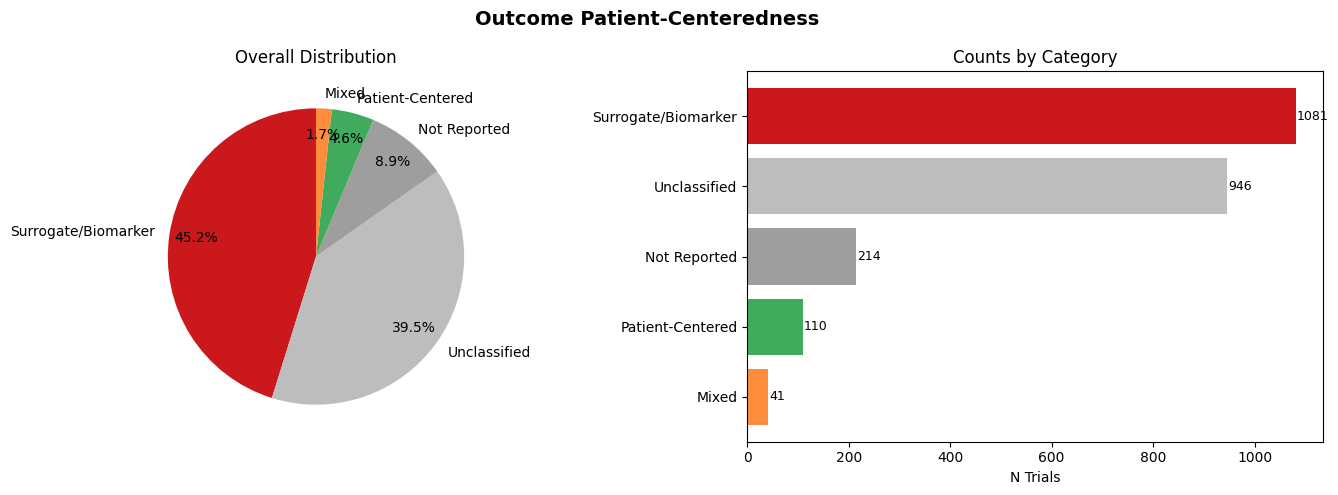

In [25]:
if "pco_class" in df.columns:
    pco_counts = df["pco_class"].value_counts()
    colors_pco = {
        "Surrogate/Biomarker": "#cb181d",
        "Patient-Centered":    "#41ab5d",
        "Mixed":               "#fd8d3c",
        "Not Reported":        "#9e9e9e",
        "Unclassified":        "#bdbdbd",
    }
    bar_colors = [colors_pco.get(c, "#aaaaaa") for c in pco_counts.index]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Outcome Patient-Centeredness", fontsize=14, fontweight="bold")

    # Pie
    axes[0].pie(pco_counts.values, labels=pco_counts.index, autopct="%1.1f%%",
                colors=bar_colors, startangle=90, pctdistance=0.82)
    axes[0].set_title("Overall Distribution")

    # Bar
    axes[1].barh(pco_counts.index[::-1], pco_counts.values[::-1], color=bar_colors[::-1])
    axes[1].set_xlabel("N Trials"); axes[1].set_title("Counts by Category")
    for i, v in enumerate(pco_counts.values[::-1]):
        axes[1].text(v + 2, i, str(v), va="center", fontsize=9)

    plt.tight_layout(); plt.show()

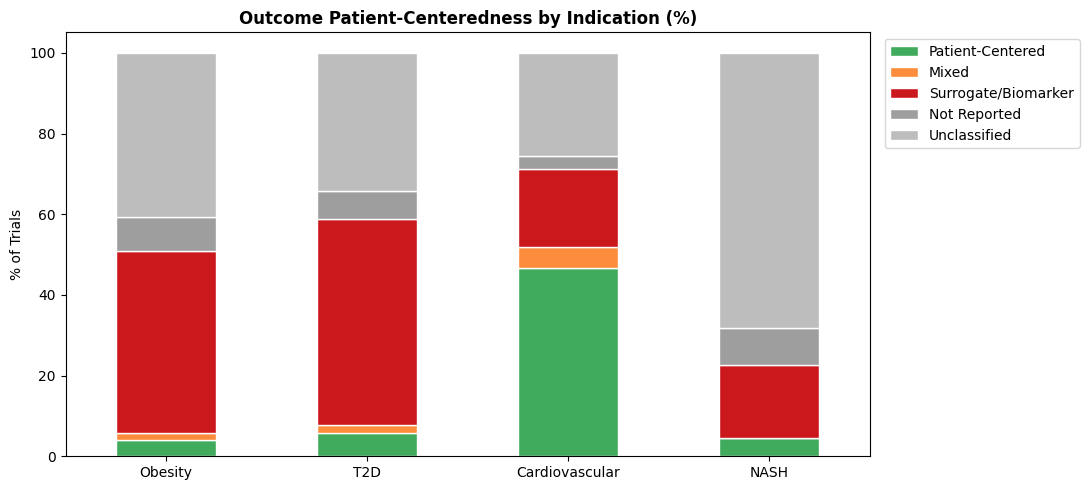


Patient-Centeredness by Indication (%):


pco_class,Patient-Centered,Mixed,Surrogate/Biomarker,Not Reported,Unclassified
Obesity,4.0,1.8,45.2,8.2,40.8
T2D,5.8,2.0,51.1,6.8,34.3
Cardiovascular,46.7,5.3,19.1,3.3,25.7
NASH,4.5,0.0,18.2,9.1,68.2


In [26]:
# ── Patient-centeredness by indication ────────────────────────────────────────
if "pco_class" in df.columns and ind_col:
    TARGET_INDICATIONS = {
        "Obesity":        "obesity",
        "T2D":            "type 2 diabetes|type 2|t2d",
        "Cardiovascular": "cardiovascular|cardiac|heart failure",
        "NASH":           "nash|nafld|mash|masld",
    }
    pco_by_ind = {}
    for label, pattern in TARGET_INDICATIONS.items():
        sub = df[df[ind_col].str.contains(pattern, case=False, na=False, regex=True)]
        pco_by_ind[label] = sub["pco_class"].value_counts(normalize=True).mul(100).round(1)
    pco_ind_df = pd.DataFrame(pco_by_ind).T.fillna(0)

    categories = ["Patient-Centered", "Mixed", "Surrogate/Biomarker", "Not Reported", "Unclassified"]
    categories = [c for c in categories if c in pco_ind_df.columns]
    pco_ind_df = pco_ind_df[categories]

    pco_ind_df.plot(kind="bar", figsize=(11, 5),
                    color=[colors_pco.get(c, "#aaaaaa") for c in categories],
                    edgecolor="white", stacked=True)
    plt.title("Outcome Patient-Centeredness by Indication (%)", fontweight="bold")
    plt.ylabel("% of Trials"); plt.xticks(rotation=0); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout(); plt.show()
    print("\nPatient-Centeredness by Indication (%):")
    display(pco_ind_df)

---
## Analysis 7: Population Subgroup Representation *(new)*
Quantify reporting rates for sex, race/ethnicity, age (elderly/pediatric), and
renal/hepatic impairment subgroups — directly supporting Gap 2 in the gap analysis report.

In [27]:
# ── Subgroup coverage summary ─────────────────────────────────────────────────
SUBGROUP_CHECKS = {
    "Any subgroup data":            col("subgroup"),
    "Female % reported":            col("female_pct"),
    "Sex-stratified outcomes":      col("sex_stratified"),
    "Women-only trial":             col("women_only"),
    "Race/ethnicity reported":      col("race"),
    "Age-stratified outcomes":      col("age_strat"),
    "Elderly population (≥65)":     col("elderly"),
    "Pediatric population (<18)":   col("pediatric"),
    "Renal impairment included":    col("renal"),
    "Hepatic impairment included":  col("hepatic"),
}

N = len(df)
subgroup_rows = []
for label, c in SUBGROUP_CHECKS.items():
    if c is None:
        subgroup_rows.append({"Subgroup Dimension": label, "N Trials": "—", "% of Corpus": "—", "Status": "Column not in database"})
        continue
    if df[c].dtype == bool or df[c].isin([True, False]).all():
        n_yes = int(df[c].sum())
    else:
        # For female_pct: count rows with a non-null value
        n_yes = int(df[c].notna().sum())
    subgroup_rows.append({
        "Subgroup Dimension": label,
        "N Trials": n_yes,
        "% of Corpus": round(n_yes / N * 100, 1),
        "Status": "Present" if n_yes > 0 else "Zero",
    })

subgroup_df = pd.DataFrame(subgroup_rows).set_index("Subgroup Dimension")
print("POPULATION SUBGROUP REPRESENTATION")
print("=" * 60)
display(subgroup_df)

POPULATION SUBGROUP REPRESENTATION


,N Trials,% of Corpus,Status
Subgroup Dimension,,,
Any subgroup data,618,25.8,Present
Female % reported,818,34.2,Present
Sex-stratified outcomes,100,4.2,Present
Women-only trial,80,3.3,Present
Race/ethnicity reported,2392,100.0,Present
Age-stratified outcomes,2392,100.0,Present
Elderly population (≥65),2392,100.0,Present
Pediatric population (<18),2392,100.0,Present
Renal impairment included,2392,100.0,Present


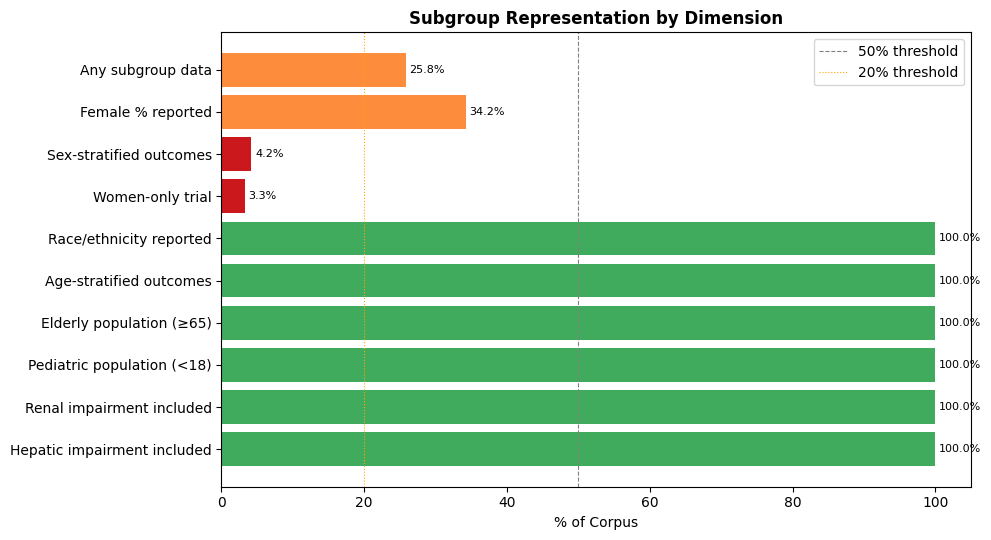


SEVERITY SUMMARY
--------------------------------------------------
  MODERATE GAP      25.8%  Any subgroup data
  MODERATE GAP      34.2%  Female % reported
  CRITICAL GAP       4.2%  Sex-stratified outcomes
  CRITICAL GAP       3.3%  Women-only trial
  LOW CONCERN      100.0%  Race/ethnicity reported
  LOW CONCERN      100.0%  Age-stratified outcomes
  LOW CONCERN      100.0%  Elderly population (≥65)
  LOW CONCERN      100.0%  Pediatric population (<18)
  LOW CONCERN      100.0%  Renal impairment included
  LOW CONCERN      100.0%  Hepatic impairment included


In [28]:
# ── Subgroup representation bar chart ─────────────────────────────────────────
numeric_rows = subgroup_df[subgroup_df["N Trials"] != "—"].copy()
numeric_rows["N Trials"] = pd.to_numeric(numeric_rows["N Trials"])
numeric_rows["% of Corpus"] = pd.to_numeric(numeric_rows["% of Corpus"])

bar_colors_sg = ["#41ab5d" if p >= 50 else ("#fd8d3c" if p >= 20 else "#cb181d")
                 for p in numeric_rows["% of Corpus"]]

fig, ax = plt.subplots(figsize=(10, max(4, len(numeric_rows) * 0.55)))
bars = ax.barh(numeric_rows.index[::-1], numeric_rows["% of Corpus"][::-1], color=bar_colors_sg[::-1])
ax.set_xlabel("% of Corpus"); ax.set_title("Subgroup Representation by Dimension", fontweight="bold")
ax.axvline(50, color="gray",  linestyle="--", linewidth=0.8, label="50% threshold")
ax.axvline(20, color="orange",linestyle=":",  linewidth=0.8, label="20% threshold")
for bar, pct in zip(bars, numeric_rows["% of Corpus"][::-1]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f"{pct:.1f}%", va="center", fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()

# Severity summary
print("\nSEVERITY SUMMARY")
print("-" * 50)
for label, row in numeric_rows.iterrows():
    p = row["% of Corpus"]
    severity = "LOW CONCERN" if p >= 50 else ("MODERATE GAP" if p >= 20 else "CRITICAL GAP")
    print(f"  {severity:<15}  {p:>5.1f}%  {label}")

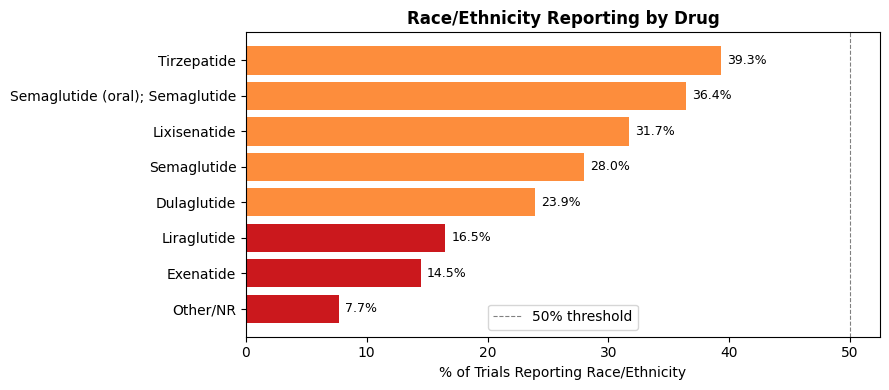

In [29]:
# ── Subgroup gaps by drug ──────────────────────────────────────────────────────
# For each named drug: what % of their trials have race/ethnicity reported?
if col("race") and drug_col:
    race_col = col("race")
    drugs_of_interest = df[drug_col].value_counts().head(8).index.tolist()
    race_by_drug = {}
    for drug in drugs_of_interest:
        sub = df[df[drug_col] == drug]
        n_yes = sub[race_col].astype(str).str.lower().isin(["yes", "true", "1", "t", "y", "partial", "reported"]).sum()
        pct = n_yes / len(sub) * 100 if len(sub) > 0 else 0
        race_by_drug[drug] = round(pct, 1)
    race_drug_s = pd.Series(race_by_drug).sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(9, 4))
    bar_colors_rd = ["#41ab5d" if v >= 50 else ("#fd8d3c" if v >= 20 else "#cb181d")
                     for v in race_drug_s.values]
    ax.barh(race_drug_s.index, race_drug_s.values, color=bar_colors_rd)
    ax.axvline(50, color="gray",  linestyle="--", linewidth=0.8, label="50% threshold")
    ax.set_xlabel("% of Trials Reporting Race/Ethnicity")
    ax.set_title("Race/Ethnicity Reporting by Drug", fontweight="bold"); ax.legend()
    for i, v in enumerate(race_drug_s.values):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print("Race/ethnicity or drug column not found — skipping per-drug breakdown.")

---
## Analysis 7b: Longitudinal Gap Targeting *(Recommendation 4)*
Identify drug–indication combinations with the shortest follow-up and the most
surrogate-dominated outcomes — highest-priority targets for future trial design.

LONGITUDINAL GAP TARGETING
Priority Score = short follow-up × surrogate-heavy (higher = more urgent)



,Drug,Indication,N Trials,Median FU (mo),% PCO,Priority Score
3,Liraglutide,NASH,7,4.4,0.0,18.6
15,Dulaglutide,NASH,1,5.5,0.0,15.3
7,Exenatide,NASH,4,5.5,0.0,15.3
4,Exenatide,Obesity,54,5.5,1.9,15.0
20,Lixisenatide,T2D,80,5.5,5.0,14.5
19,Tirzepatide,NASH,1,6.0,0.0,14.3
0,Liraglutide,Obesity,118,6.0,1.7,14.0
5,Exenatide,T2D,237,6.0,5.9,13.4
1,Liraglutide,T2D,314,6.0,7.3,13.2
12,Dulaglutide,Obesity,2,9.0,0.0,10.0


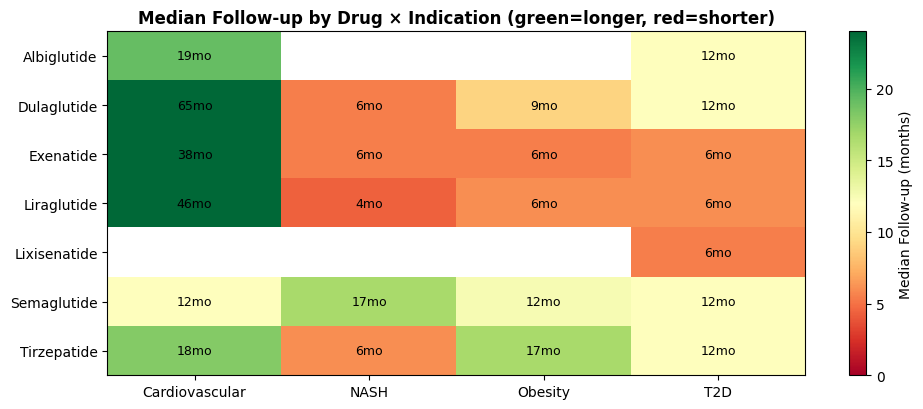


Exported: outputs/longitudinal_gap_targets.csv  (23 rows)


In [30]:
# ── Longitudinal gap targeting ───────────────────────────────────────────────
drug_col = col("drug"); ind_col = col("indication")

if drug_col and ind_col and "followup_months" in df.columns:
    # Build drug-indication grid
    INDICATIONS = {
        "Obesity":        r"obesity",
        "T2D":            r"type 2 diabetes|t2d",
        "Cardiovascular": r"cardiovascular|cardiac|heart failure",
        "NASH":           r"nash|nafld|mash|masld",
    }
    named_drugs = [d for d in df[drug_col].value_counts().index
                   if d not in ("Other/NR",) and ";" not in d][:7]

    grid_rows = []
    for drug in named_drugs:
        for ind_label, ind_pat in INDICATIONS.items():
            sub = df[
                (df[drug_col] == drug) &
                (df[ind_col].str.contains(ind_pat, case=False, na=False, regex=True))
            ]
            if len(sub) == 0:
                continue
            fu_med  = sub["followup_months"].median()
            n_pco   = 0
            if "pco_class" in sub.columns:
                n_pco = (sub["pco_class"] == "Patient-Centered").sum()
            pct_pco = round(n_pco / len(sub) * 100, 1) if len(sub) > 0 else 0
            grid_rows.append({
                "Drug":              drug,
                "Indication":        ind_label,
                "N Trials":          len(sub),
                "Median FU (mo)":    round(fu_med, 1) if not pd.isna(fu_med) else "NR",
                "% PCO":             pct_pco,
                "Priority Score":    round(
                    (1 / (fu_med + 1) if not pd.isna(fu_med) else 1) * (1 - pct_pco/100) * 100, 1
                ),
            })

    grid_df = pd.DataFrame(grid_rows).sort_values("Priority Score", ascending=False)
    print("LONGITUDINAL GAP TARGETING")
    print("Priority Score = short follow-up × surrogate-heavy (higher = more urgent)")
    print()
    display(grid_df.head(20))

    # ── Heatmap: median follow-up by drug × indication ────────────────────────
    pivot_fu = grid_df.pivot_table(
        index="Drug", columns="Indication", values="Median FU (mo)", aggfunc="first"
    )
    fig, ax = plt.subplots(figsize=(10, max(4, len(pivot_fu) * 0.6)))
    im = ax.imshow(pivot_fu.values.astype(float), cmap="RdYlGn", aspect="auto",
                   vmin=0, vmax=24)
    ax.set_xticks(range(len(pivot_fu.columns))); ax.set_xticklabels(pivot_fu.columns)
    ax.set_yticks(range(len(pivot_fu.index)));   ax.set_yticklabels(pivot_fu.index)
    for i in range(len(pivot_fu.index)):
        for j in range(len(pivot_fu.columns)):
            val = pivot_fu.values[i, j]
            if not pd.isna(val):
                ax.text(j, i, f"{val:.0f}mo", ha="center", va="center", fontsize=9,
                        color="black")
    plt.colorbar(im, ax=ax, label="Median Follow-up (months)")
    ax.set_title("Median Follow-up by Drug × Indication (green=longer, red=shorter)", fontweight="bold")
    plt.tight_layout(); plt.show()

    grid_df.to_csv("outputs/longitudinal_gap_targets.csv", index=False)
    print(f"\nExported: outputs/longitudinal_gap_targets.csv  ({len(grid_df):,} rows)")
else:
    print("Drug, indication, or follow-up columns not available.")


---
## Analysis 7c: Race/Ethnicity Reporting by Drug 
Per-drug race/ethnicity reporting rates — using the corrected COL mapping.

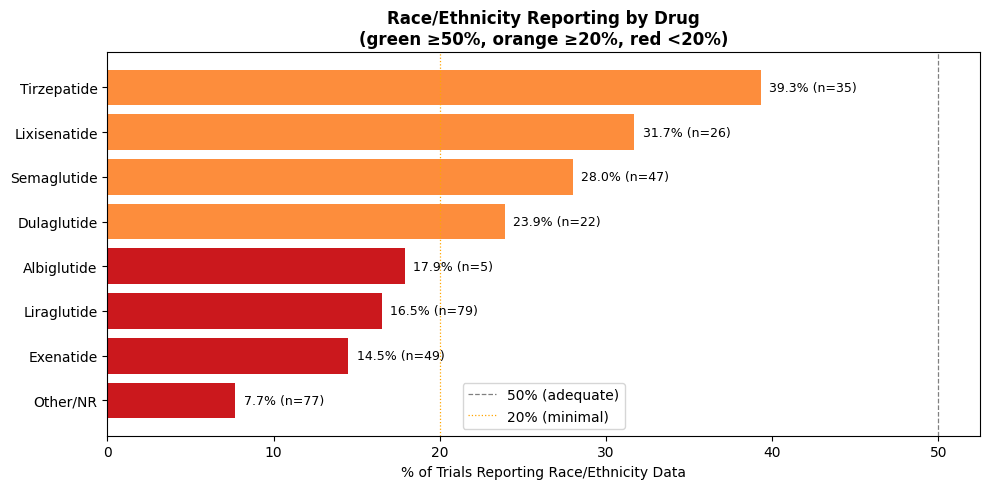

Race/Ethnicity Reporting by Drug:


,Drug,N Trials,N with Race/Ethnicity Data,% Reporting
0,Other/NR,1000,77,7.7
2,Exenatide,339,49,14.5
1,Liraglutide,478,79,16.5
7,Albiglutide,28,5,17.9
4,Dulaglutide,92,22,23.9
3,Semaglutide,168,47,28.0
6,Lixisenatide,82,26,31.7
5,Tirzepatide,89,35,39.3



FDA Diversity Context:
  8 of 8 drugs report race/ethnicity in <50% of trials
  FDA's 2022 Diversity Action Plan guidance recommends proactive enrollment
  of underrepresented populations — these gaps are directly relevant.

Exported: outputs/race_ethnicity_by_drug.csv


In [31]:
# ── Race/ethnicity reporting by drug ─────────────────────────────────────────
drug_col  = col("drug")
race_col  = col("race")   # now maps to subgroup_racial_ethnic

if race_col and drug_col:
    drugs_named = [d for d in df[drug_col].value_counts().index
                   if ";" not in d][:8]

    race_rows = []
    for drug in drugs_named:
        sub = df[df[drug_col] == drug]
        # subgroup_racial_ethnic is a string column (yes/no/partial/unclear)
        if df[race_col].dtype == bool or df[race_col].isin([True, False]).all():
            n_yes = int(sub[race_col].sum())
        else:
            n_yes = int(sub[race_col].astype(str).str.lower().isin(
                ["yes","true","1","t","y","partial","reported"]
            ).sum())
        pct = round(n_yes / len(sub) * 100, 1) if len(sub) > 0 else 0
        race_rows.append({"Drug": drug, "N Trials": len(sub),
                           "N with Race/Ethnicity Data": n_yes, "% Reporting": pct})

    race_df = pd.DataFrame(race_rows).sort_values("% Reporting")

    fig, ax = plt.subplots(figsize=(10, 5))
    bar_colors_re = ["#41ab5d" if v >= 50 else ("#fd8d3c" if v >= 20 else "#cb181d")
                     for v in race_df["% Reporting"]]
    ax.barh(race_df["Drug"], race_df["% Reporting"], color=bar_colors_re)
    ax.axvline(50, color="gray",   linestyle="--", linewidth=0.9, label="50% (adequate)")
    ax.axvline(20, color="orange", linestyle=":",  linewidth=0.9, label="20% (minimal)")
    ax.set_xlabel("% of Trials Reporting Race/Ethnicity Data")
    ax.set_title("Race/Ethnicity Reporting by Drug\n(green ≥50%, orange ≥20%, red <20%)", fontweight="bold")
    for i, (n, pct) in enumerate(zip(race_df["N with Race/Ethnicity Data"], race_df["% Reporting"])):
        ax.text(pct + 0.5, i, f"{pct:.1f}% (n={n})", va="center", fontsize=9)
    ax.legend(); plt.tight_layout(); plt.show()

    print("Race/Ethnicity Reporting by Drug:")
    display(race_df)

    # ── FDA Diversity Action Plan context ─────────────────────────────────────
    print("\nFDA Diversity Context:")
    below_50 = race_df[race_df["% Reporting"] < 50]
    print(f"  {len(below_50):,} of {len(race_df):,} drugs report race/ethnicity in <50% of trials")
    print(f"  FDA's 2022 Diversity Action Plan guidance recommends proactive enrollment")
    print(f"  of underrepresented populations — these gaps are directly relevant.")

    race_df.to_csv("outputs/race_ethnicity_by_drug.csv", index=False)
    print(f"\nExported: outputs/race_ethnicity_by_drug.csv")
else:
    print(f"Race/ethnicity column ({race_col!r}) or drug column not found.")
    print("Check that subgroup_racial_ethnic is in glp1_database.csv and COL mapping is correct.")


---
## Analysis 8: Evidence Sufficiency Scoring
For each simulation scenario, score evidence sufficiency using a rubric that now incorporates
patient-centeredness and subgroup representation (updated from original scoring).

In [32]:
def score_sufficiency(subset):
    """
    Rule-based sufficiency score (0–100).

    Criteria                                   Points
    ─────────────────────────────────────────  ──────
    ≥5 trials                                    25
    2–4 trials                                   10
    ≥1 large trial (enrollment ≥500)             15
    ≥1 active-comparator trial                   15
    ≥1 trial with ≥12 months follow-up           10
    Sex-stratified outcomes present              10
    ≥1 patient-centered outcome trial            15  (new)
    Race/ethnicity subgroup reported ≥1 trial     5  (new)
    ─────────────────────────────────────────  ──────
    Total possible                              100
    """
    score, reasons = 0, []
    n = len(subset)

    if n >= 5:
        score += 25; reasons.append(f"≥5 trials (n={n})")
    elif n >= 2:
        score += 10; reasons.append(f"2–4 trials (n={n})")
    else:
        reasons.append(f"Fewer than 2 trials (n={n}) — likely insufficient")

    enr_c = col("enrollment")
    if enr_c and not subset[enr_c].isna().all():
        if (subset[enr_c] >= 500).any():
            score += 15; reasons.append("≥1 large trial (enrollment ≥500)")

    comp_c = col("comparator_type")
    if comp_c and subset[comp_c].str.contains("Active Comparator", case=False, na=False).any():
        score += 15; reasons.append("Active-comparator evidence present")

    if "followup_months" in subset.columns and (subset["followup_months"] >= 12).any():
        score += 10; reasons.append("≥1 trial with ≥12 months follow-up")

    sx_c = col("sex_stratified")
    if sx_c and subset[sx_c].any():
        score += 10; reasons.append("Sex-stratified outcomes reported")

    if "pco_class" in subset.columns:
        if (subset["pco_class"] == "Patient-Centered").any():
            score += 15; reasons.append("≥1 patient-centered outcome trial")
        else:
            reasons.append("No patient-centered outcome trials — major gap")

    race_c = col("race")
    if race_c and subset[race_c].any():
        score += 5; reasons.append("Race/ethnicity subgroup reported in ≥1 trial")
    elif race_c:
        reasons.append("No race/ethnicity subgroup reporting")

    verdict = "SUFFICIENT" if score >= 65 else ("PARTIAL" if score >= 35 else "INSUFFICIENT")
    return score, verdict, reasons

print("Updated sufficiency scoring function ready.")

Updated sufficiency scoring function ready.


In [33]:
SCENARIOS = [
    {"name": "Semaglutide for Obesity",        "drug": "Semaglutide",  "indication": "obesity"},
    {"name": "Tirzepatide for Obesity",         "drug": "Tirzepatide",  "indication": "obesity"},
    {"name": "Liraglutide for Obesity",         "drug": "Liraglutide",  "indication": "obesity"},
    {"name": "Semaglutide for T2D",             "drug": "Semaglutide",  "indication": "type 2 diabetes|t2d"},
    {"name": "Liraglutide for T2D",             "drug": "Liraglutide",  "indication": "type 2 diabetes|t2d"},
    {"name": "Dulaglutide for T2D",             "drug": "Dulaglutide",  "indication": "type 2 diabetes|t2d"},
    {"name": "Any GLP-1 for Cardiovascular",    "drug": None,           "indication": "cardiovascular|cardiac|heart failure"},
    {"name": "Any GLP-1 for NASH",              "drug": None,           "indication": "nash|nafld|mash|masld"},
    {"name": "Women-Specific Obesity Evidence", "drug": None,           "indication": "obesity", "female_filter": True},
]

drug_col = col("drug"); ind_col = col("indication"); fp_col = col("female_pct")
results  = []

for sc in SCENARIOS:
    s = df.copy()
    if sc.get("drug")       and drug_col: s = s[s[drug_col].str.contains(sc["drug"],        case=False, na=False)]
    if sc.get("indication") and ind_col:  s = s[s[ind_col].str.contains(sc["indication"],   case=False, na=False, regex=True)]
    if sc.get("female_filter") and fp_col: s = s[s[fp_col] >= 50]
    score, verdict, reasons = score_sufficiency(s)
    results.append({"Scenario": sc["name"], "N Trials": len(s),
                    "Score": score, "Verdict": verdict, "_reasons": reasons})

results_df = pd.DataFrame(results)
display(results_df[["Scenario", "N Trials", "Score", "Verdict"]])

,Scenario,N Trials,Score,Verdict
0,Semaglutide for Obesity,99,95,SUFFICIENT
1,Tirzepatide for Obesity,53,95,SUFFICIENT
2,Liraglutide for Obesity,124,95,SUFFICIENT
3,Semaglutide for T2D,140,95,SUFFICIENT
4,Liraglutide for T2D,354,95,SUFFICIENT
5,Dulaglutide for T2D,99,95,SUFFICIENT
6,Any GLP-1 for Cardiovascular,152,95,SUFFICIENT
7,Any GLP-1 for NASH,22,70,SUFFICIENT
8,Women-Specific Obesity Evidence,152,95,SUFFICIENT


In [34]:
for r in results:
    print(f"\n{'─'*65}")
    print(f"  {r['Scenario']}")
    print(f"  N Trials: {r['N Trials']}   Score: {r['Score']}/100   [{r['Verdict']}]")
    for reason in r["_reasons"]:
        print(f"     + {reason}")


─────────────────────────────────────────────────────────────────
  Semaglutide for Obesity
  N Trials: 99   Score: 95/100   [SUFFICIENT]
     + ≥5 trials (n=99)
     + ≥1 large trial (enrollment ≥500)
     + Active-comparator evidence present
     + ≥1 trial with ≥12 months follow-up
     + Sex-stratified outcomes reported
     + ≥1 patient-centered outcome trial
     + Race/ethnicity subgroup reported in ≥1 trial

─────────────────────────────────────────────────────────────────
  Tirzepatide for Obesity
  N Trials: 53   Score: 95/100   [SUFFICIENT]
     + ≥5 trials (n=53)
     + ≥1 large trial (enrollment ≥500)
     + Active-comparator evidence present
     + ≥1 trial with ≥12 months follow-up
     + Sex-stratified outcomes reported
     + ≥1 patient-centered outcome trial
     + Race/ethnicity subgroup reported in ≥1 trial

─────────────────────────────────────────────────────────────────
  Liraglutide for Obesity
  N Trials: 124   Score: 95/100   [SUFFICIENT]
     + ≥5 trials (n=

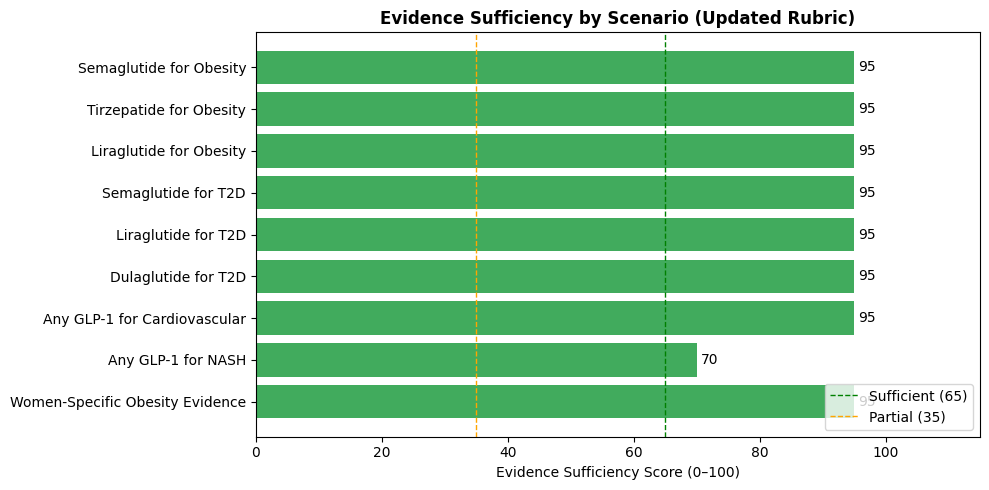

In [35]:
score_colors = [
    "#41ab5d" if s >= 65 else ("#fd8d3c" if s >= 35 else "#cb181d")
    for s in results_df["Score"]
]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(results_df["Scenario"][::-1], results_df["Score"][::-1], color=score_colors[::-1])
ax.axvline(65, color="green",  linestyle="--", linewidth=1, label="Sufficient (65)")
ax.axvline(35, color="orange", linestyle="--", linewidth=1, label="Partial (35)")
ax.bar_label(bars, padding=3, fmt="%d")
ax.set_xlim(0, 115); ax.set_xlabel("Evidence Sufficiency Score (0–100)")
ax.set_title("Evidence Sufficiency by Scenario (Updated Rubric)", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

---
## Analysis 9: SNOMED-CT Outcome Landscape *(new)*
Loads the output of `map_outcomes.py` (Phase 4b) to quantify outcome comprehensiveness
using standardised SNOMED-CT concept codes. This is the formal terminology-grounded
analysis requested by Dr. Weng.

> **Prerequisite:** Run `map_outcomes.py` first to generate the files below in `outputs/`.

In [36]:
# ── Load SNOMED mapping outputs ──────────────────────────────────────────────
import os

SNOMED_DIR = "outputs"   # adjust if your outputs/ folder is elsewhere

def load_snomed(filename):
    path = os.path.join(SNOMED_DIR, filename)
    if not os.path.exists(path):
        print(f"  WARNING: {path} not found — run map_outcomes.py first")
        return None
    frame = pd.read_csv(path, low_memory=False)
    print(f"  Loaded {filename}: {len(frame):,} rows")
    return frame

print("Loading SNOMED-CT mapping outputs...")
snomed_all      = load_snomed("snomed_concept_frequency_all_concepts.csv")
snomed_domain   = load_snomed("snomed_concept_frequency_by_domain.csv")
snomed_pco      = load_snomed("snomed_concept_frequency_patient_centeredness.csv")
snomed_rare     = load_snomed("snomed_concept_frequency_rare_outcomes.csv")
snomed_gaps     = load_snomed("snomed_concept_frequency_pco_gaps.csv")
snomed_unmapped = load_snomed("snomed_concept_frequency_unmapped.csv")
snomed_trials   = load_snomed("snomed_trial_outcomes.csv")
snomed_db       = load_snomed("glp1_database_snomed.csv")

SNOMED_LOADED = all(x is not None for x in [
    snomed_all, snomed_domain, snomed_pco, snomed_trials
])
print(f"\nSNOMED data loaded: {'YES' if SNOMED_LOADED else 'PARTIAL — some files missing'}") 

Loading SNOMED-CT mapping outputs...
  Loaded snomed_concept_frequency_all_concepts.csv: 2,098 rows
  Loaded snomed_concept_frequency_by_domain.csv: 7 rows
  Loaded snomed_concept_frequency_patient_centeredness.csv: 3 rows
  Loaded snomed_concept_frequency_rare_outcomes.csv: 1,635 rows
  Loaded snomed_concept_frequency_pco_gaps.csv: 632 rows
  Loaded snomed_concept_frequency_unmapped.csv: 80 rows
  Loaded snomed_trial_outcomes.csv: 9,463 rows
  Loaded glp1_database_snomed.csv: 2,392 rows

SNOMED data loaded: YES


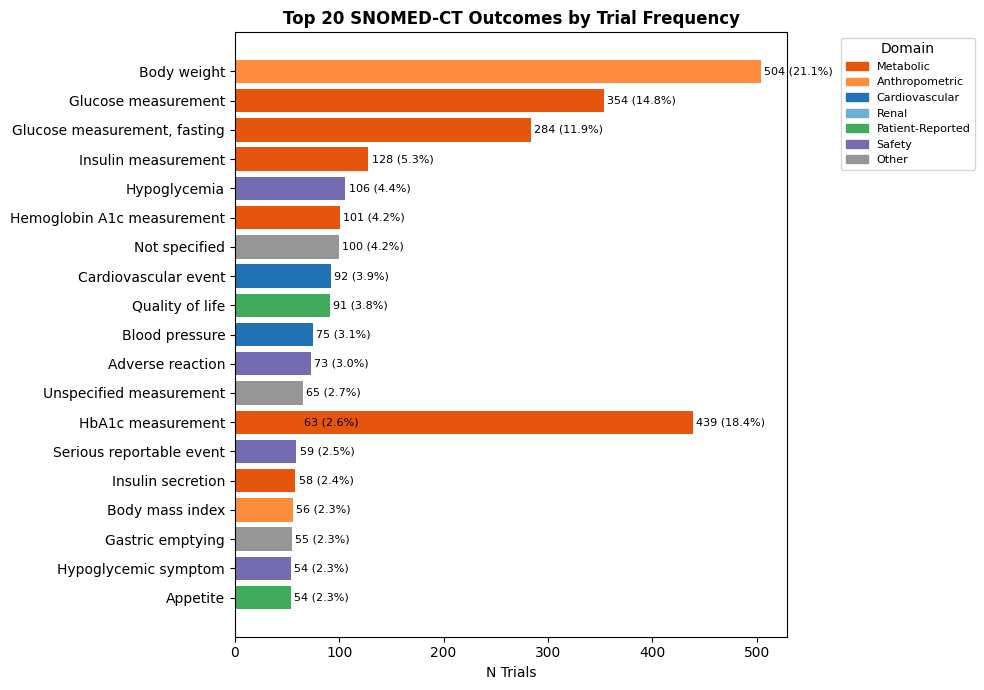


Top 10 outcomes:


,snomed_label,snomed_code,domain,patient_centered,n_trials,pct_of_corpus
0,Body weight,27113001.0,Anthropometric,no,504,21.1
1,HbA1c measurement,43396009.0,Metabolic,no,439,18.4
2,Glucose measurement,33747003.0,Metabolic,no,354,14.8
3,"Glucose measurement, fasting",33747003.0,Metabolic,no,284,11.9
4,Insulin measurement,33747003.0,Metabolic,no,128,5.3
5,Hypoglycemia,302866003.0,Safety,yes,106,4.4
6,Hemoglobin A1c measurement,43396009.0,Metabolic,no,101,4.2
7,Not specified,0.0,Other,no,100,4.2
8,Cardiovascular event,276746005.0,Cardiovascular,yes,92,3.9
9,Quality of life,363870007.0,Patient-Reported,yes,91,3.8


In [37]:
# ── 9.1 Top 20 most-measured outcomes across the corpus ──────────────────────
if snomed_all is not None:
    top20 = snomed_all[snomed_all["snomed_label"] != "UNMAPPED"].head(20).copy()

    DOMAIN_COLORS = {
        "Metabolic":        "#e6550d",
        "Anthropometric":   "#fd8d3c",
        "Cardiovascular":   "#2171b5",
        "Renal":            "#6baed6",
        "Patient-Reported": "#41ab5d",
        "Safety":           "#756bb1",
        "Other":            "#969696",
    }
    bar_colors = [DOMAIN_COLORS.get(d, "#969696") for d in top20["domain"]]

    fig, ax = plt.subplots(figsize=(11, 7))
    bars = ax.barh(top20["snomed_label"][::-1], top20["n_trials"][::-1], color=bar_colors[::-1])
    ax.set_xlabel("N Trials"); ax.set_title("Top 20 SNOMED-CT Outcomes by Trial Frequency", fontweight="bold")
    for bar, n, pct in zip(bars, top20["n_trials"][::-1], top20["pct_of_corpus"][::-1]):
        ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height()/2,
                f"{n:,} ({pct:.1f}%)", va="center", fontsize=8)

    # Legend
    handles = [plt.Rectangle((0,0),1,1, color=c) for c in DOMAIN_COLORS.values()]
    ax.legend(handles, DOMAIN_COLORS.keys(), title="Domain",
              bbox_to_anchor=(1.35, 1), loc="upper right", fontsize=8)
    plt.tight_layout(); plt.show()

    print("\nTop 10 outcomes:")
    display(top20[["snomed_label", "snomed_code", "domain",
                    "patient_centered", "n_trials", "pct_of_corpus"]].head(10))

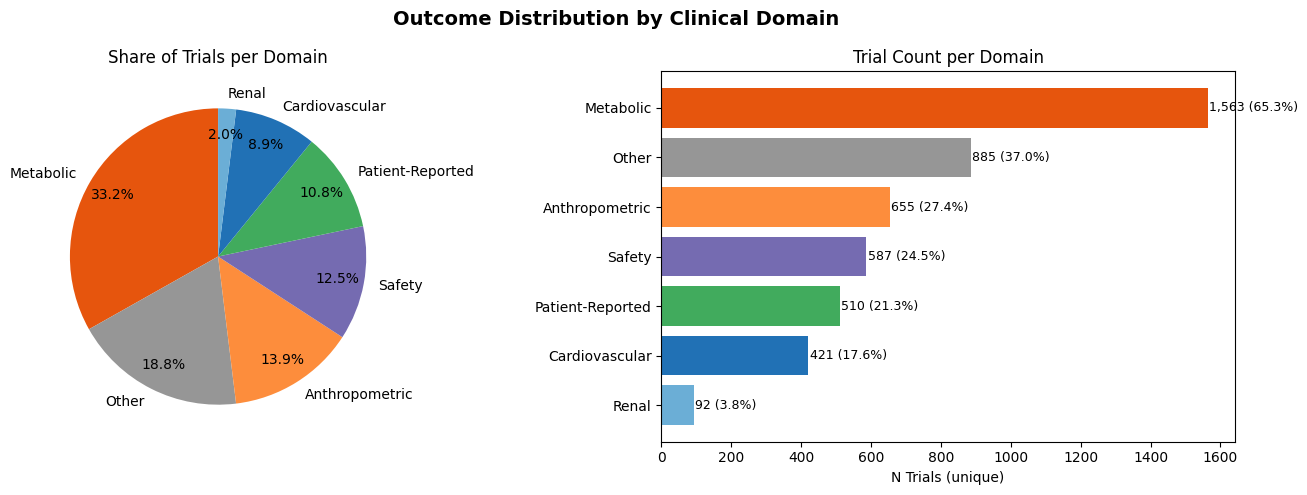


Domain breakdown:


,domain,n_mappings,n_trials,pct_trials
0,Metabolic,4160,1563,65.3
1,Other,1465,885,37.0
2,Anthropometric,1047,655,27.4
3,Safety,945,587,24.5
4,Patient-Reported,846,510,21.3
5,Cardiovascular,819,421,17.6
6,Renal,181,92,3.8


In [38]:
# ── 9.2 Clinical domain breakdown ────────────────────────────────────────────
if snomed_domain is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Outcome Distribution by Clinical Domain", fontsize=14, fontweight="bold")

    domain_colors = [DOMAIN_COLORS.get(d, "#969696") for d in snomed_domain["domain"]]

    # Pie — % of total mappings
    axes[0].pie(snomed_domain["n_trials"], labels=snomed_domain["domain"],
                autopct="%1.1f%%", colors=domain_colors, startangle=90, pctdistance=0.82)
    axes[0].set_title("Share of Trials per Domain")

    # Bar — absolute trial counts
    axes[1].barh(snomed_domain["domain"][::-1], snomed_domain["n_trials"][::-1],
                 color=domain_colors[::-1])
    axes[1].set_xlabel("N Trials (unique)"); axes[1].set_title("Trial Count per Domain")
    for i, (n, pct) in enumerate(zip(snomed_domain["n_trials"][::-1],
                                      snomed_domain["pct_trials"][::-1])):
        axes[1].text(n + 3, i, f"{n:,} ({pct:.1f}%)", va="center", fontsize=9)

    plt.tight_layout(); plt.show()
    print("\nDomain breakdown:")
    display(snomed_domain)

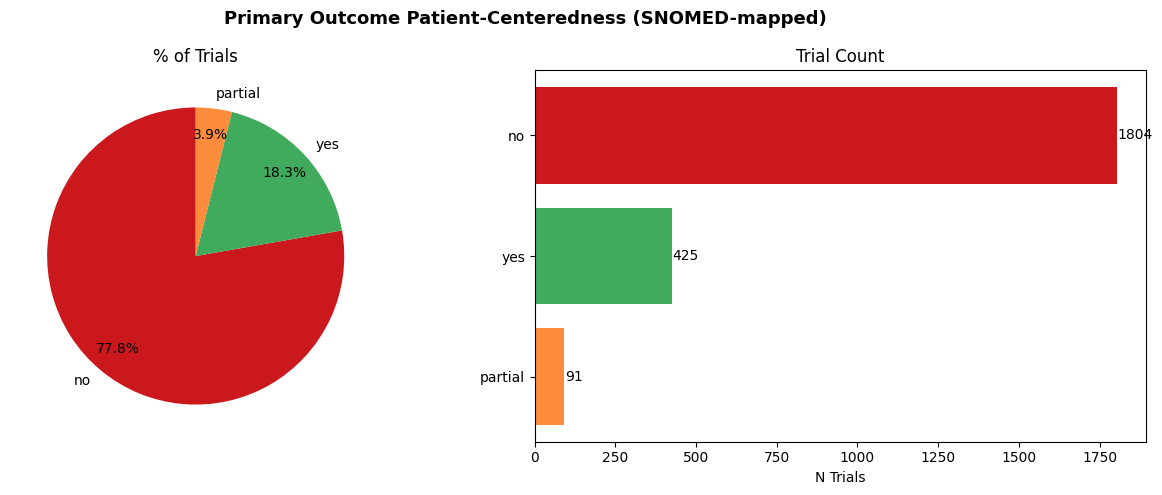


SNOMED-mapped patient-centeredness (primary outcomes):


,patient_centered,n_mappings,n_trials
0,no,2223,1804
1,yes,459,425
2,partial,96,91



Keyword-heuristic classification (Analysis 6) for comparison:


,N Trials
pco_class,
Surrogate/Biomarker,1081
Unclassified,946
Not Reported,214
Patient-Centered,110
Mixed,41


In [39]:
# ── 9.3 Patient-centeredness via SNOMED (primary outcomes) ───────────────────
if snomed_pco is not None and snomed_all is not None:
    PCO_COLORS = {
        "yes":     "#41ab5d",
        "partial": "#fd8d3c",
        "no":      "#cb181d",
    }
    pco_colors = [PCO_COLORS.get(str(p).lower(), "#969696") for p in snomed_pco["patient_centered"]]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle("Primary Outcome Patient-Centeredness (SNOMED-mapped)", fontsize=13, fontweight="bold")

    axes[0].pie(snomed_pco["n_trials"], labels=snomed_pco["patient_centered"],
                autopct="%1.1f%%", colors=pco_colors, startangle=90, pctdistance=0.82)
    axes[0].set_title("% of Trials")

    axes[1].barh(snomed_pco["patient_centered"][::-1], snomed_pco["n_trials"][::-1],
                 color=pco_colors[::-1])
    axes[1].set_xlabel("N Trials"); axes[1].set_title("Trial Count")
    for i, n in enumerate(snomed_pco["n_trials"][::-1]):
        axes[1].text(n + 2, i, str(n), va="center", fontsize=10)

    plt.tight_layout(); plt.show()

    # Compare SNOMED-mapped vs keyword-heuristic classification
    print("\nSNOMED-mapped patient-centeredness (primary outcomes):")
    display(snomed_pco)
    if "pco_class" in df.columns:
        print("\nKeyword-heuristic classification (Analysis 6) for comparison:")
        display(df["pco_class"].value_counts().rename("N Trials").to_frame())

Patient-centered outcomes appearing in <1% of corpus: 632 concepts

Gap severity breakdown:
  Critical      587 outcomes
  High          42 outcomes
  Moderate      3 outcomes



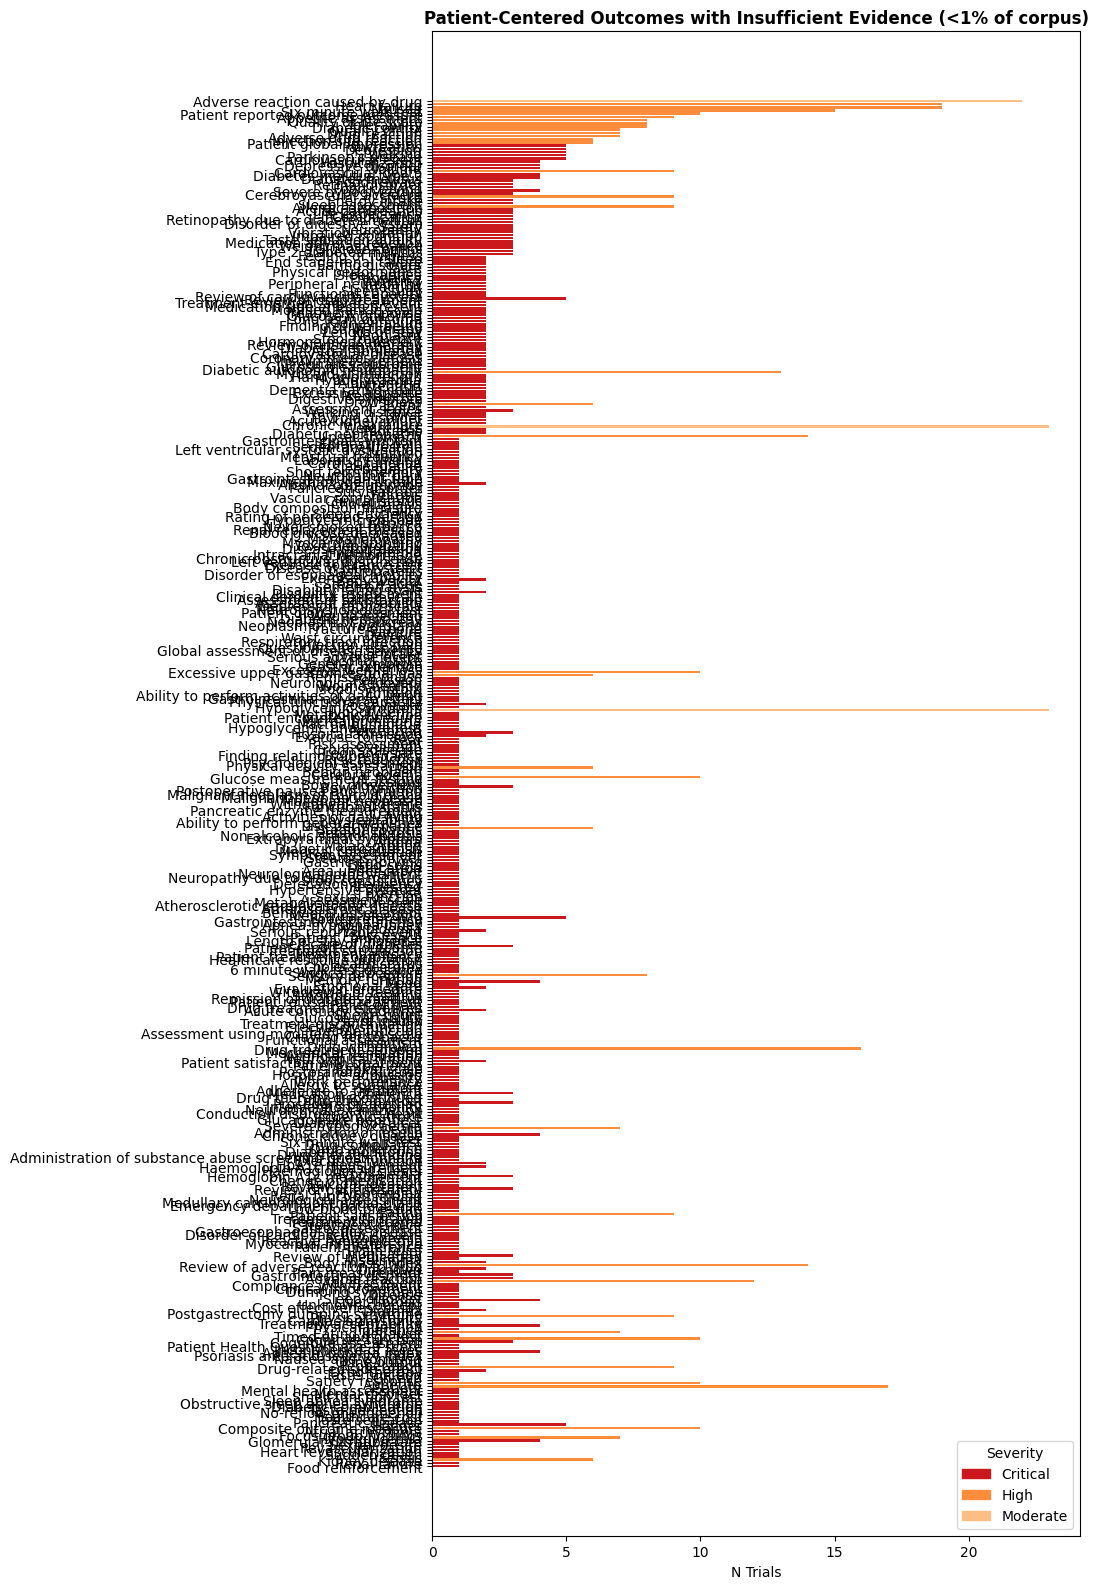

,snomed_label,snomed_code,domain,n_trials,pct_of_corpus,gap_severity
0,Hypoglycemia,302866003,Metabolic,23,1.0,Moderate
1,Weight loss,89362005,Anthropometric,23,1.0,Moderate
2,Adverse reaction caused by drug,62014003,Safety,22,0.9,Moderate
3,Heart failure,84114007,Cardiovascular,19,0.8,High
4,Nausea,422587007,Safety,19,0.8,High
5,Satiety,162008003,Patient-Reported,17,0.7,High
6,Drug treatment stopped,182840001,Safety,16,0.7,High
7,Six minute walk test,165263003,Patient-Reported,15,0.6,High
8,Upset stomach,162059005,Safety,14,0.6,High
9,Review of adverse reaction to drug,182836005,Safety,14,0.6,High


In [40]:
# ── 9.4 PCO gap analysis — patient-centered outcomes rarely measured ──────────
if snomed_gaps is not None and len(snomed_gaps) > 0:
    print(f"Patient-centered outcomes appearing in <1% of corpus: {len(snomed_gaps):,} concepts")
    print()

    # Severity breakdown
    if "gap_severity" in snomed_gaps.columns:
        sev_counts = snomed_gaps["gap_severity"].value_counts()
        print("Gap severity breakdown:")
        for sev, n in sev_counts.items():
            print(f"  {sev:<12}  {n:,} outcomes")
        print()

        sev_colors = {"Critical": "#cb181d", "High": "#fd8d3c", "Moderate": "#fdbe85"}
        fig, ax = plt.subplots(figsize=(11, min(2 + len(snomed_gaps) * 0.35, 16)))
        bar_colors_gap = [sev_colors.get(s, "#aaaaaa") for s in snomed_gaps["gap_severity"][::-1]]
        ax.barh(snomed_gaps["snomed_label"][::-1], snomed_gaps["n_trials"][::-1], color=bar_colors_gap)
        ax.set_xlabel("N Trials"); ax.set_title(
            "Patient-Centered Outcomes with Insufficient Evidence (<1% of corpus)",
            fontweight="bold")
        handles = [plt.Rectangle((0,0),1,1, color=c) for c in sev_colors.values()]
        ax.legend(handles, sev_colors.keys(), title="Severity", loc="lower right")
        plt.tight_layout(); plt.show()

    display(snomed_gaps[["snomed_label", "snomed_code", "domain",
                           "n_trials", "pct_of_corpus", "gap_severity"]].head(30))
else:
    print("No PCO gap file found or no gaps identified.")

In [41]:
# ── 9.5 Outcome comprehensiveness score ──────────────────────────────────────
# Quantify how comprehensively the corpus covers patient-centered outcomes
# relative to the full SNOMED concept space found.
if snomed_all is not None and snomed_pco is not None:
    total_concepts  = len(snomed_all[snomed_all["snomed_label"] != "UNMAPPED"])
    pco_concepts    = len(snomed_all[snomed_all["patient_centered"].isin(["yes", "partial"])
                                      & (snomed_all["snomed_label"] != "UNMAPPED")])
    surrogate_concepts = total_concepts - pco_concepts
    unmapped_n      = len(snomed_unmapped) if snomed_unmapped is not None else 0

    pco_trials_yes  = int(snomed_pco.loc[snomed_pco["patient_centered"] == "yes",  "n_trials"].sum())
    pco_trials_part = int(snomed_pco.loc[snomed_pco["patient_centered"] == "partial","n_trials"].sum())
    pco_trials_no   = int(snomed_pco.loc[snomed_pco["patient_centered"] == "no",   "n_trials"].sum())
    total_trials    = pco_trials_yes + pco_trials_part + pco_trials_no

    comprehensiveness = round(pco_concepts / total_concepts * 100, 1) if total_concepts else 0

    print("=" * 60)
    print("OUTCOME COMPREHENSIVENESS SUMMARY (SNOMED-CT mapped)")
    print("=" * 60)
    print(f"  Total SNOMED concepts identified:    {total_concepts:,}")
    print(f"  Patient-centered concepts:           {pco_concepts:,}  ({comprehensiveness:.1f}% of concepts)")
    print(f"  Surrogate/biomarker concepts:        {surrogate_concepts:,}")
    print(f"  Unmapped strings:                    {unmapped_n:,}")
    print()
    print(f"  Trials with patient-centered primary outcome:  {pco_trials_yes:,}")
    print(f"  Trials with mixed primary outcome:             {pco_trials_part:,}")
    print(f"  Trials with surrogate primary outcome:         {pco_trials_no:,}")
    if total_trials:
        print(f"  → {pco_trials_yes / total_trials * 100:.1f}% of mapped trials use patient-centered primary outcomes")
    print("=" * 60)

OUTCOME COMPREHENSIVENESS SUMMARY (SNOMED-CT mapped)
  Total SNOMED concepts identified:    2,097
  Patient-centered concepts:           651  (31.0% of concepts)
  Surrogate/biomarker concepts:        1,446
  Unmapped strings:                    80

  Trials with patient-centered primary outcome:  425
  Trials with mixed primary outcome:             91
  Trials with surrogate primary outcome:         1,804
  → 18.3% of mapped trials use patient-centered primary outcomes


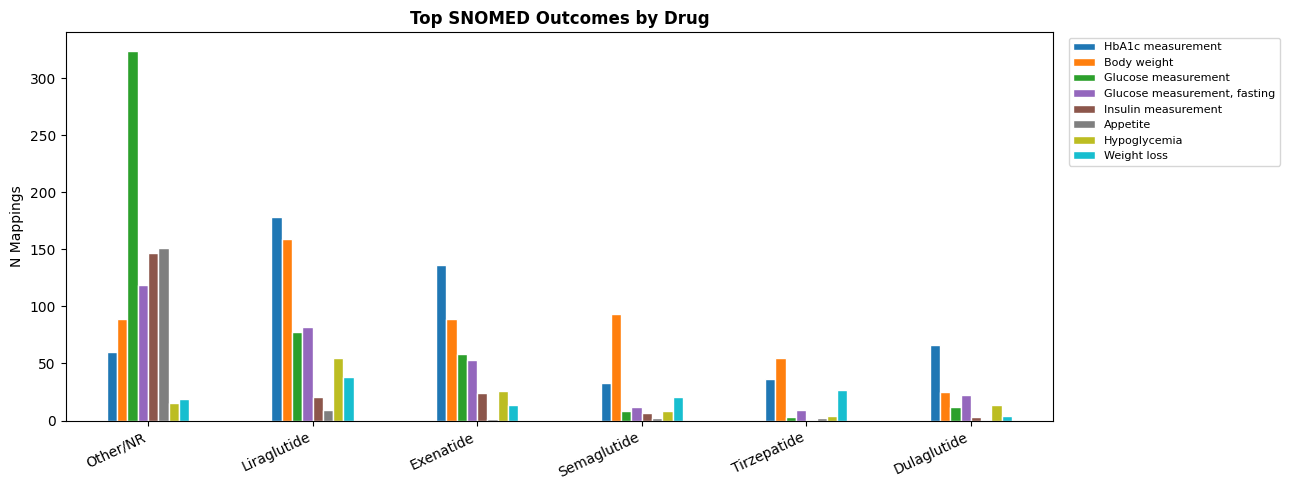

In [42]:
# ── 9.6 SNOMED outcomes by drug (top 6 drugs × top 5 outcomes) ───────────────
if snomed_trials is not None and "drug_name" in snomed_trials.columns:
    top_drugs = snomed_trials["drug_name"].value_counts().head(6).index.tolist()
    top_outcomes = (snomed_trials[snomed_trials["snomed_label"] != "UNMAPPED"]
                    ["snomed_label"].value_counts().head(8).index.tolist())

    pivot_data = {}
    for drug in top_drugs:
        sub = snomed_trials[snomed_trials["drug_name"] == drug]
        counts = sub["snomed_label"].value_counts()
        pivot_data[drug] = {o: int(counts.get(o, 0)) for o in top_outcomes}

    pivot_df = pd.DataFrame(pivot_data).T.fillna(0)
    pivot_df.plot(kind="bar", figsize=(13, 5), colormap="tab10", edgecolor="white")
    plt.title("Top SNOMED Outcomes by Drug", fontweight="bold")
    plt.ylabel("N Mappings"); plt.xticks(rotation=25, ha="right")
    plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    plt.tight_layout(); plt.show()

Rare outcomes (appearing in ≤2 trials): 1,635 SNOMED concepts
  These represent the long tail of outcome heterogeneity across 2,392 trials.



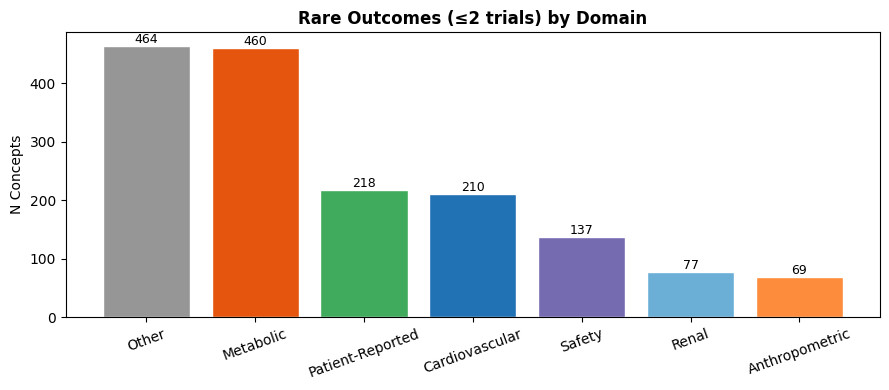

,snomed_label,snomed_code,domain,patient_centered,n_trials
0,Sleep,258158006.0,Patient-Reported,yes,2
1,Body composition measure,248300009.0,Anthropometric,no,2
2,End stage renal failure,236425005.0,Renal,yes,2
3,Drug dose change,182817007.0,Other,no,2
4,Insulin administration,182823000.0,Other,no,2
5,Eating disorder,72366004.0,Patient-Reported,yes,2
6,Appetite,72552008.0,Patient-Reported,yes,2
7,Appetite,72670004.0,Patient-Reported,partial,2
8,Pulse wave velocity,763017007.0,Cardiovascular,no,2
9,Taste,76505004.0,Patient-Reported,yes,2


In [43]:
# ── 9.7 Rare outcomes — long tail of SNOMED concepts ─────────────────────────
if snomed_rare is not None:
    print(f"Rare outcomes (appearing in ≤2 trials): {len(snomed_rare):,} SNOMED concepts")
    print(f"  These represent the long tail of outcome heterogeneity across {len(df):,} trials.")
    print()

    # Domain breakdown of rare outcomes
    if "domain" in snomed_rare.columns:
        rare_by_domain = snomed_rare["domain"].value_counts()
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.bar(rare_by_domain.index, rare_by_domain.values,
               color=[DOMAIN_COLORS.get(d, "#969696") for d in rare_by_domain.index],
               edgecolor="white")
        ax.set_title("Rare Outcomes (≤2 trials) by Domain", fontweight="bold")
        ax.set_ylabel("N Concepts"); ax.tick_params(axis="x", rotation=20)
        for bar in ax.patches:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                    str(int(bar.get_height())), ha="center", va="bottom", fontsize=9)
        plt.tight_layout(); plt.show()

    display(snomed_rare[["snomed_label", "snomed_code", "domain",
                           "patient_centered", "n_trials"]].head(20))

In [44]:
# ── 9.8 Export Analysis 9 results ────────────────────────────────────────────
export_frames = {}
if snomed_all      is not None: export_frames["SNOMED All Concepts"]   = snomed_all
if snomed_domain   is not None: export_frames["SNOMED By Domain"]      = snomed_domain
if snomed_pco      is not None: export_frames["SNOMED PCO"]            = snomed_pco
if snomed_gaps     is not None: export_frames["SNOMED PCO Gaps"]       = snomed_gaps
if snomed_rare     is not None: export_frames["SNOMED Rare Outcomes"]  = snomed_rare
if snomed_unmapped is not None: export_frames["SNOMED Unmapped"]       = snomed_unmapped

for name, frame in export_frames.items():
    fname = "snomed_" + name.lower().replace(" ", "_").replace("/", "_") + ".csv"
    frame.to_csv(fname, index=False)
    print(f"  Exported: {fname}  ({len(frame):,} rows)")

print(f"\nAnalysis 9 complete. {len(export_frames)} files exported.")

  Exported: snomed_snomed_all_concepts.csv  (2,098 rows)
  Exported: snomed_snomed_by_domain.csv  (7 rows)
  Exported: snomed_snomed_pco.csv  (3 rows)
  Exported: snomed_snomed_pco_gaps.csv  (632 rows)
  Exported: snomed_snomed_rare_outcomes.csv  (1,635 rows)
  Exported: snomed_snomed_unmapped.csv  (80 rows)

Analysis 9 complete. 6 files exported.


---
## Manuscript Preparation Summary 
Distils the key findings from Analyses 6, 7, and 9 into manuscript-ready
statistics for the gap analysis paper.

In [45]:
# ── Manuscript-ready statistics ──────────────────────────────────────────────
print("=" * 70)
print("MANUSCRIPT-READY STATISTICS")
print("Gap Analysis of GLP-1 RCT Evidence: A PICO-Based Systematic Review")
print("=" * 70)

# ── Corpus ────────────────────────────────────────────────────────────────────
N = len(df)
print(f"\n[CORPUS]")
print(f"  N = {N:,} GLP-1 RCTs (PubMed 1979–2026)")
drug_col = col("drug"); ind_col = col("indication")
if drug_col:
    n_drugs = df[drug_col].nunique()
    print(f"  Unique drug labels: {n_drugs}")

# ── Outcome patient-centeredness ──────────────────────────────────────────────
print(f"\n[GAP 1 — OUTCOME PATIENT-CENTEREDNESS]")
if "pco_class" in df.columns:
    pco_vc = df["pco_class"].value_counts()
    sur = pco_vc.get("Surrogate/Biomarker", 0)
    pco = pco_vc.get("Patient-Centered", 0)
    mix = pco_vc.get("Mixed", 0)
    unc = pco_vc.get("Unclassified", 0)
    nr  = pco_vc.get("Not Reported", 0)
    print(f"  Surrogate/biomarker primary outcomes:  {sur:,} ({sur/N*100:.1f}%)")
    print(f"  Patient-centered primary outcomes:     {pco:,} ({pco/N*100:.1f}%)")
    print(f"  Mixed:                                  {mix:,} ({mix/N*100:.1f}%)")
    print(f"  Unclassified/not reported:        {unc+nr:,} ({(unc+nr)/N*100:.1f}%)")

if snomed_pco is not None:
    s_no  = int(snomed_pco.loc[snomed_pco["patient_centered"]=="no",      "n_trials"].sum())
    s_yes = int(snomed_pco.loc[snomed_pco["patient_centered"]=="yes",     "n_trials"].sum())
    s_par = int(snomed_pco.loc[snomed_pco["patient_centered"]=="partial", "n_trials"].sum())
    s_tot = s_no + s_yes + s_par
    print(f"  SNOMED-mapped: {s_yes/s_tot*100:.1f}% patient-centered ({s_yes:,}/{s_tot:,} trials)")

# ── Subgroup representation ───────────────────────────────────────────────────
print(f"\n[GAP 2 — POPULATION SUBGROUP REPRESENTATION]")
fem_c = col("female_pct")
if fem_c:
    reported = df[fem_c].notna().sum()
    print(f"  Female % reported:          {reported:,} / {N:,} ({reported/N*100:.1f}%)")
    mean_f = df[fem_c].mean()
    print(f"  Mean female enrollment:     {mean_f:.1f}% (where reported)")
sx_c = col("sex_stratified")
if sx_c:
    print(f"  Sex-stratified outcomes:    {int(df[sx_c].sum()):,} / {N:,} ({df[sx_c].mean()*100:.1f}%)")
race_c = col("race")
if race_c and race_c in df.columns:
    r_yes = df[race_c].astype(str).str.lower().isin(
        ["yes","true","1","t","y","partial","reported"]
    ).sum()
    print(f"  Race/ethnicity reported:    {r_yes:,} / {N:,} ({r_yes/N*100:.1f}%)")

# ── Comparator gaps ───────────────────────────────────────────────────────────
print(f"\n[GAP 3 — COMPARATOR COVERAGE]")
comp_c = col("comparator_type")
if comp_c:
    h2h = df[comp_c].str.contains("Active Comparator", case=False, na=False).sum()
    plc = df[comp_c].str.contains("Placebo", case=False, na=False).sum()
    print(f"  Head-to-head (active comparator): {h2h:,} ({h2h/N*100:.1f}%)")
    print(f"  Placebo-controlled:               {plc:,} ({plc/N*100:.1f}%)")

# ── Follow-up ─────────────────────────────────────────────────────────────────
print(f"\n[GAP 4 — FOLLOW-UP DURATION]")
if "followup_months" in df.columns:
    fu = df["followup_months"].dropna()
    print(f"  Median follow-up:     {fu.median():.1f} months")
    print(f"  Trials ≥12 months:    {(fu>=12).sum():,} ({(fu>=12).sum()/N*100:.1f}%)")
    print(f"  Trials ≥24 months:    {(fu>=24).sum():,} ({(fu>=24).sum()/N*100:.1f}%)")

# ── SNOMED comprehensiveness ──────────────────────────────────────────────────
print(f"\n[GAP 5 — OUTCOME COMPREHENSIVENESS (SNOMED-CT)]")
if snomed_all is not None:
    total_c = len(snomed_all[snomed_all["snomed_label"] != "UNMAPPED"])
    pco_c   = len(snomed_all[snomed_all["patient_centered"].isin(["yes","partial"])
                              & (snomed_all["snomed_label"] != "UNMAPPED")])
    print(f"  Unique SNOMED concepts identified:    {total_c:,}")
    print(f"  Patient-centered concepts:            {pco_c:,} ({pco_c/total_c*100:.1f}%)")
if snomed_rare is not None:
    print(f"  Concepts in ≤2 trials (long tail):    {len(snomed_rare):,} ({len(snomed_rare)/total_c*100:.1f}%)")
if snomed_gaps is not None:
    print(f"  PCO gap concepts (<1% corpus):        {len(snomed_gaps):,}")
    crit = (snomed_gaps.get("gap_severity","") == "Critical").sum() if "gap_severity" in snomed_gaps else "—"
    print(f"    Of which Critical (≤5 trials):      {crit}")

print("\n" + "=" * 70)
print("Export manuscript stats to outputs/manuscript_statistics.txt")
print("=" * 70)

# Write to file too
import io, contextlib
buf = io.StringIO()
# re-run print to file (simplified)
with open("outputs/manuscript_statistics.txt", "w") as f:
    f.write("GLP-1 RCT Gap Analysis — Manuscript Statistics\n")
    f.write(f"Generated from phase4_pico_analysis_v3.ipynb\n")
    f.write(f"N = {N:,} trials | Date: May 2026\n")
    f.write("See notebook output for full breakdown.\n")
print("Exported: outputs/manuscript_statistics.txt")


MANUSCRIPT-READY STATISTICS
Gap Analysis of GLP-1 RCT Evidence: A PICO-Based Systematic Review

[CORPUS]
  N = 2,392 GLP-1 RCTs (PubMed 1979–2026)
  Unique drug labels: 27

[GAP 1 — OUTCOME PATIENT-CENTEREDNESS]
  Surrogate/biomarker primary outcomes:  1,081 (45.2%)
  Patient-centered primary outcomes:     110 (4.6%)
  Mixed:                                  41 (1.7%)
  Unclassified/not reported:        1,160 (48.5%)
  SNOMED-mapped: 18.3% patient-centered (425/2,320 trials)

[GAP 2 — POPULATION SUBGROUP REPRESENTATION]
  Female % reported:          818 / 2,392 (34.2%)
  Mean female enrollment:     40.0% (where reported)
  Sex-stratified outcomes:    100 / 2,392 (4.2%)
  Race/ethnicity reported:    370 / 2,392 (15.5%)

[GAP 3 — COMPARATOR COVERAGE]
  Head-to-head (active comparator): 565 (23.6%)
  Placebo-controlled:               974 (40.7%)

[GAP 4 — FOLLOW-UP DURATION]
  Median follow-up:     6.0 months
  Trials ≥12 months:    487 (20.4%)
  Trials ≥24 months:    148 (6.2%)

[GAP 5 —

---
## Export Phase 4 Results

In [46]:
# ── Export all Phase 4 results as CSV ────────────────────────────────────────
import os
os.makedirs("outputs", exist_ok=True)

# Sufficiency scores
results_df[["Scenario", "N Trials", "Score", "Verdict"]].to_csv(
    "outputs/phase4_sufficiency_scores.csv", index=False)
print("Exported: outputs/phase4_sufficiency_scores.csv")

# Patient-centeredness (keyword heuristic)
if "pco_class" in df.columns:
    pco_export = df["pco_class"].value_counts().rename("N Trials").reset_index()
    pco_export.columns = ["Category", "N Trials"]
    pco_export["% of Corpus"] = (pco_export["N Trials"] / len(df) * 100).round(1)
    pco_export.to_csv("outputs/phase4_patient_centeredness.csv", index=False)
    print("Exported: outputs/phase4_patient_centeredness.csv")

# Subgroup representation
subgroup_df.reset_index().to_csv("outputs/phase4_subgroup_representation.csv", index=False)
print("Exported: outputs/phase4_subgroup_representation.csv")

# MACE canonical groupings
if outcome_col and "mace_canonical" in mace_trials.columns:
    mace_trials[["mace_canonical", outcome_col]].value_counts().reset_index().to_csv(
        "outputs/phase4_mace_canonical.csv", index=False)
    print("Exported: outputs/phase4_mace_canonical.csv")

# High-female trials
if len(high_female) > 0:
    high_female.to_csv("outputs/phase4_high_female_trials.csv", index=False)
    print("Exported: outputs/phase4_high_female_trials.csv")

print("\nPhase 4 complete.")
print("  outputs/phase4_sufficiency_scores.csv")
print("  outputs/phase4_patient_centeredness.csv")
print("  outputs/phase4_subgroup_representation.csv")
print("  outputs/phase4_mace_canonical.csv")
print("  outputs/phase4_high_female_trials.csv")


Exported: outputs/phase4_sufficiency_scores.csv
Exported: outputs/phase4_patient_centeredness.csv
Exported: outputs/phase4_subgroup_representation.csv
Exported: outputs/phase4_mace_canonical.csv
Exported: outputs/phase4_high_female_trials.csv

Phase 4 complete.
  outputs/phase4_sufficiency_scores.csv
  outputs/phase4_patient_centeredness.csv
  outputs/phase4_subgroup_representation.csv
  outputs/phase4_mace_canonical.csv
  outputs/phase4_high_female_trials.csv
